# Phân tích các yếu tố ảnh hưởng đến rating người dùng trên MovieLens bằng cách kết hợp dữ liệu thông tin phim (TMDb)

In [175]:
import pandas as pd
import numpy as np
import re
import json
import ast
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, silhouette_score, accuracy_score


In [176]:
warnings.filterwarnings('ignore')

# --- 1. ĐỊNH NGHĨA HÀM XỬ LÝ ---
def clean_movielens_title(text):
    return re.sub(r'\s*\(\d{4}\)$', '', str(text)).lower().strip()

def clean_tmdb_title(text):
    return str(text).lower().strip()

def get_director(text):
    try:
        data = ast.literal_eval(text)
        for x in data:
            if x['job'] == 'Director': return x['name']
        return np.nan
    except: return np.nan

def get_top_actors(text):
    try:
        data = ast.literal_eval(text)
        return [x['name'] for x in data[:3]]
    except: return []

## Chuẩn bị Dữ liệu (Data Preparation)

In [177]:
# --- 2. TẢI DỮ LIỆU ---
print("Đang tải dữ liệu...")
u_cols = ['UserID', 'Gender', 'Age', 'Occupation', 'Zip-code']
m_cols = ['MovieID', 'Title', 'Genres']
r_cols = ['UserID', 'MovieID', 'Rating', 'Timestamp']

users = pd.read_csv('datasets/movie_len_1M/users.dat', sep='::', names=u_cols, encoding='latin-1', engine='python')
movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=m_cols, encoding='latin-1', engine='python')
ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=r_cols, encoding='latin-1', engine='python')

# --- TÍNH ĐIỂM TRUNG BÌNH (AVG_RATING) ---
print("Đang tính toán điểm trung bình cho từng phim...")
movie_targets = ratings.groupby('MovieID')['Rating'].mean().reset_index()
movie_targets.columns = ['MovieID', 'avg_rating']

Đang tải dữ liệu...
Đang tính toán điểm trung bình cho từng phim...


In [178]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   UserID      6040 non-null   int64 
 1   Gender      6040 non-null   object
 2   Age         6040 non-null   int64 
 3   Occupation  6040 non-null   int64 
 4   Zip-code    6040 non-null   object
dtypes: int64(3), object(2)
memory usage: 236.1+ KB


**Các ý nghĩa của từng cột trong bảng Users**:
| Cột (Column)   | Ý nghĩa |
|----------------|---------|
| **UserID**     | Mã định danh của người dùng (ID duy nhất). |
| **Gender**     | Giới tính của người dùng (M/F). |
| **Age**        | Nhóm tuổi hoặc mã tuổi của người dùng (ví dụ: 1 = dưới 18, 18, 25, 35...). |
| **Occupation** | Mã nghề nghiệp của người dùng (một số nguyên biểu diễn từng loại nghề khác nhau). |
| **Zip-code**   | Mã bưu điện (ZIP) hoặc khu vực mà người dùng sinh sống. |


In [179]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   MovieID  3883 non-null   int64 
 1   Title    3883 non-null   object
 2   Genres   3883 non-null   object
dtypes: int64(1), object(2)
memory usage: 91.1+ KB


**Các ý nghĩa của từng cột trong bảng Movies**:
| Cột (Column) | Ý nghĩa |
|--------------|---------|
| **MovieID**  | ID duy nhất của phim trong hệ thống MovieLens. |
| **Title**    | Tên phim kèm năm phát hành (ví dụ: *Toy Story (1995)*). |
| **Genres**   | Các thể loại phim, phân tách bằng dấu `|` (ví dụ: *Animation|Children's|Comedy*). |


In [180]:
ratings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   UserID     1000209 non-null  int64
 1   MovieID    1000209 non-null  int64
 2   Rating     1000209 non-null  int64
 3   Timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB


**Các ý nghĩa của từng cột trong bảng Ratings**:
| Cột (Column) | Ý nghĩa |
|--------------|---------|
| **UserID**   | ID người dùng đã đánh giá phim. |
| **MovieID**  | ID của bộ phim được đánh giá. |
| **Rating**   | Điểm đánh giá do người dùng chấm (thường từ 1 đến 5). |
| **Timestamp**| Thời điểm đánh giá (dạng UNIX timestamp – số giây tính từ 1/1/1970). |


In [181]:
# --- 3. XỬ LÝ DỮ LIỆU TMDB ---
try:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='utf-8')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='utf-8')
except:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='latin-1')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='latin-1')

tmdb_cred.columns = ['movie_id', 'title', 'cast', 'crew']
tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})
tmdb_full = pd.merge(tmdb_mov, tmdb_cred, on='movie_id')

print(f"Loaded & Merged TMDB: {tmdb_full.shape}")

Loaded & Merged TMDB: (4803, 23)


In [182]:
tmdb_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   movie_id              4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

**Giải thích ý nghĩa của các cột**
| Cột (Column)           | Ý nghĩa |
|------------------------|---------|
| **budget**             | Ngân sách sản xuất phim (USD). |
| **genres**             | Thể loại phim, lưu dưới dạng chuỗi JSON (Action, Comedy…). |
| **homepage**           | Trang web chính thức của bộ phim. |
| **movie_id**           | ID phim trong cơ sở dữ liệu TheMovieDB. |
| **keywords**           | Các từ khóa mô tả nội dung phim. |
| **original_language**  | Ngôn ngữ gốc của phim (ví dụ: `en`, `fr`). |
| **original_title**     | Tên gốc của bộ phim. |
| **overview**           | Tóm tắt nội dung phim. |
| **popularity**         | Mức độ phổ biến của phim trên TMDB. |
| **production_companies** | Danh sách công ty sản xuất phim (JSON string). |
| **production_countries** | Danh sách quốc gia sản xuất phim. |
| **release_date**       | Ngày phát hành phim. |
| **revenue**            | Doanh thu phòng vé (USD). |
| **runtime**            | Thời lượng phim (phút). |
| **spoken_languages**   | Danh sách ngôn ngữ được sử dụng trong phim. |
| **status**             | Tình trạng phát hành (Released, Post Production…). |
| **tagline**            | Slogan/tagline của phim. |
| **title**              | Tên phim phát hành chính thức. |
| **vote_average**       | Điểm đánh giá trung bình trên TMDB. |
| **vote_count**         | Số lượt đánh giá. |
| **tittle_credits**     | Thông tin credit khi merge, có thể là lỗi chính tả của `title_credits`. |
| **cast**               | Danh sách diễn viên của phim (JSON string). |
| **crew**               | Danh sách nhân sự (đạo diễn, biên kịch…) của phim (JSON string). |


In [183]:
# --- 3. HIỂN THỊ DỮ LIỆU MẪU ĐỂ KIỂM TRA ---

print("\n--- Sample Users ---")
users.head(3)


--- Sample Users ---


,UserID,Gender,Age,Occupation,Zip-code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117


In [184]:
print("\n--- Sample Movies ---")
movies.head(3)


--- Sample Movies ---


,MovieID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


In [185]:
print("\n--- Sample Ratings ---")
ratings.head(3)


--- Sample Ratings ---


,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968


In [186]:
print("\n--- Sample TMDB Credits ---")
tmdb_cred.head(3)


--- Sample TMDB Credits ---


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."


In [187]:
print("\n--- Sample TMDB Movies ---")
tmdb_mov.head(3)


--- Sample TMDB Movies ---


,budget,genres,homepage,movie_id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466


## Tiền xử lý dữ liệu (Data Preprocessing)

### Chuẩn hóa (Data Normalization)

In [188]:
# --- 3. XỬ LÝ DỮ LIỆU TMDB (SỬA LẠI ĐỂ TRÁNH LỖI TITLE) ---
print("Đang tải và xử lý TMDB...")
try:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='utf-8')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='utf-8')
except:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='latin-1')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='latin-1')

# --- ĐIỂM SỬA QUAN TRỌNG TẠI ĐÂY ---
# Đổi tên cột title của credits thành 'tittle_cr' để không trùng với 'title' của bảng movies
tmdb_cred.columns = ['movie_id', 'tittle_cr', 'cast', 'crew'] 

tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})

# Merge nội bộ TMDB
tmdb_full = pd.merge(tmdb_mov, tmdb_cred, on='movie_id')

# Kiểm tra xem cột title có tồn tại không
if 'title' not in tmdb_full.columns:
    # Trường hợp file gốc dùng 'original_title', ta tạo lại cột title
    if 'original_title' in tmdb_full.columns:
        tmdb_full['title'] = tmdb_full['original_title']

print(f"Cột trong TMDB Full: {list(tmdb_full.columns)}") 
# Bây giờ chắc chắn đã có cột 'title'

# --- 4. MERGE METADATA (CHẠY LẠI BƯỚC NÀY SẼ KHÔNG CÒN LỖI) ---
print("Đang xử lý Metadata phim...")

# Tạo khóa nối
movies['title_join'] = movies['Title'].apply(clean_movielens_title)
tmdb_full['title_join'] = tmdb_full['title'].apply(clean_tmdb_title)

# Ghép Movies gốc với TMDB
movies_meta = pd.merge(movies, tmdb_full, on='title_join', how='inner')

# Ghép thêm cột avg_rating (từ bảng movie_targets đã tạo ở bước trước)
movies_meta = pd.merge(movies_meta, movie_targets, on='MovieID', how='inner')

# Trích xuất Director, Actors, Year
movies_meta['director'] = movies_meta['crew'].apply(get_director)
movies_meta['actors_temp'] = movies_meta['cast'].apply(get_top_actors)
actors_df = movies_meta['actors_temp'].apply(pd.Series).iloc[:, :3]
actors_df.columns = ['actor_1', 'actor_2', 'actor_3']
movies_meta = pd.concat([movies_meta, actors_df], axis=1)
movies_meta['release_year'] = movies_meta['Title'].str.extract(r'\((\d{4})\)$').astype(float)

# Chọn lọc các cột metadata
cols_meta = [
    'MovieID', 'Title', 'Genres', 'release_year', 'avg_rating', 
    'director', 'actor_1', 'actor_2', 'actor_3',
    'budget', 'revenue', 'vote_average', 'vote_count', 'runtime'
]
movies_final_meta = movies_meta[cols_meta]

# --- 5. TẠO DATAFRAME CUỐI CÙNG ---
print("Đang ghép vào bảng Ratings gốc...")
df_final = pd.merge(ratings, movies_final_meta, on='MovieID', how='inner')

print("-" * 30)
print(f"Kích thước cuối cùng: {df_final.shape}")
print("5 dòng đầu tiên:")
print(df_final[['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average']].head())

Đang tải và xử lý TMDB...
Cột trong TMDB Full: ['budget', 'genres', 'homepage', 'movie_id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'tittle_cr', 'cast', 'crew']
Đang xử lý Metadata phim...
Đang ghép vào bảng Ratings gốc...
------------------------------
Kích thước cuối cùng: (450575, 17)
5 dòng đầu tiên:
   UserID                                   Title  Rating  avg_rating  \
0       1  One Flew Over the Cuckoo's Nest (1975)       5    4.390725   
1       1                     My Fair Lady (1964)       3    4.154088   
2       1                  Erin Brockovich (2000)       4    3.863878   
3       1                          Ben-Hur (1959)       5    4.110795   
4       1  Snow White and the Seven Dwarfs (1937)       4    3.845347   

   vote_average  
0           8.2  
1           7.4 

### Trích xuất đặc trưng (Feature Selection)

In [189]:
movies_merged = movies_meta.copy()

# --- 2. ÁP DỤNG VÀO DATAFRAME ---
print("Đang trích xuất dữ liệu Đạo diễn, Diễn viên và Năm phát hành...")

# 1. Reset các cột nếu đã lỡ chạy trước đó (để tránh lỗi duplicate columns)
cols_to_reset = ['director', 'actor_1', 'actor_2', 'actor_3', 'actors_list', 'release_year']
movies_merged = movies_merged.drop(columns=[c for c in cols_to_reset if c in movies_merged.columns], errors='ignore')

# 2. Trích xuất Đạo diễn (Director)
# Lưu ý: Hàm get_director phải được định nghĩa từ trước
movies_merged['director'] = movies_merged['crew'].apply(get_director)

# 3. Trích xuất Diễn viên (Actors) - CÁCH TỐI ƯU & AN TOÀN HƠN
# Lấy list diễn viên
movies_merged['actors_list'] = movies_merged['cast'].apply(get_top_actors)

# Tách list thành các cột riêng biệt
actors_df = movies_merged['actors_list'].apply(pd.Series)

# Đảm bảo luôn có đủ 3 cột (0, 1, 2) dù dữ liệu thiếu
for i in range(3):
    if i not in actors_df.columns:
        actors_df[i] = np.nan

# Chỉ lấy 3 cột đầu tiên và đổi tên
actors_df = actors_df.iloc[:, :3]
actors_df.columns = ['actor_1', 'actor_2', 'actor_3']

# Ghép vào bảng chính
movies_merged = pd.concat([movies_merged, actors_df], axis=1)

# 4. Trích xuất Năm phát hành (Release Year) từ Title của MovieLens
# Regex: Tìm 4 số nằm trong ngoặc đơn ở cuối chuỗi
movies_merged['release_year'] = movies_merged['Title'].str.extract(r'\((\d{4})\)$')
movies_merged['release_year'] = pd.to_numeric(movies_merged['release_year'], errors='coerce')

# 5. Dọn dẹp cột tạm
movies_merged = movies_merged.drop(columns=['actors_list'], errors='ignore')

# --- 3. KIỂM TRA KẾT QUẢ ---
print("-" * 30)
print("Các cột hiện có sau khi xử lý Feature Engineering:")
print(list(movies_merged.columns))

print("\n5 dòng dữ liệu mẫu (Kiểm tra Đạo diễn, Diễn viên, Năm):")
cols_check = ['Title', 'release_year', 'director', 'actor_1', 'Genres']
print(movies_merged[cols_check].head())

Đang trích xuất dữ liệu Đạo diễn, Diễn viên và Năm phát hành...
------------------------------
Các cột hiện có sau khi xử lý Feature Engineering:
['MovieID', 'Title', 'Genres', 'title_join', 'budget', 'genres', 'homepage', 'movie_id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'tittle_cr', 'cast', 'crew', 'avg_rating', 'actors_temp', 'director', 'actor_1', 'actor_2', 'actor_3', 'release_year']

5 dòng dữ liệu mẫu (Kiểm tra Đạo diễn, Diễn viên, Năm):
                     Title  release_year         director          actor_1  \
0         Toy Story (1995)          1995    John Lasseter        Tom Hanks   
1         GoldenEye (1995)          1995  Martin Campbell   Pierce Brosnan   
2             Nixon (1995)          1995     Oliver Stone  Anthony Hopkins   
3  Cutthroat Island (1995)        

### Tích hợp dữ liệu (Data Integration)

In [190]:
# --- TỐI ƯU HÓA TRƯỚC KHI MERGE ---

# 1. Chọn lọc các cột cần thiết từ bảng phim (Metadata)
# Chúng ta chỉ giữ lại những thông tin có giá trị phân tích
cols_to_keep = [
    'MovieID', 'Title',             # Định danh phim
    'Genres', 'release_year',       # Thông tin cơ bản
    'director', 'actor_1', 'actor_2', 'actor_3', # Ekip làm phim
    'budget', 'revenue',            # Tài chính
    'vote_average', 'vote_count',   # Đánh giá từ TMDB
    'avg_rating'                    # Đánh giá trung bình từ MovieLens (Đã tính ở bước trước)
]

# Lọc để chỉ lấy các cột thực sự tồn tại trong movies_merged (tránh lỗi nếu thiếu cột nào đó)
existing_cols = [c for c in cols_to_keep if c in movies_merged.columns]
movies_lean = movies_merged[existing_cols]

# 2. Thực hiện Merge cuối cùng (Big Merge)
# Ghép bảng Ratings (1 triệu dòng) với bảng Metadata phim đã lọc gọn
# Dùng 'inner' để chỉ giữ lại các rating của những phim ĐÃ CÓ thông tin từ TMDB
print("Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...")
full_data = pd.merge(ratings, movies_lean, on='MovieID', how='inner')

# --- 3. KIỂM TRA KẾT QUẢ ---
print("-" * 30)
print(f"Tổng số lượt đánh giá gốc (Ratings): {ratings.shape[0]}")
print(f"Tổng số dòng dữ liệu sau khi merge (Full Data): {full_data.shape[0]}")
print(f"-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): {ratings.shape[0] - full_data.shape[0]}")
print("-" * 30)

# Xem 5 dòng dữ liệu hoàn chỉnh để đảm bảo bạn có đủ 3 loại điểm số
# 1. Rating: Điểm do người dùng này chấm
# 2. avg_rating: Điểm trung bình của phim trên MovieLens
# 3. vote_average: Điểm trung bình của phim trên TMDB
print("5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):")
cols_check = ['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average', 'director']
print(full_data[cols_check].head())

Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...
------------------------------
Tổng số lượt đánh giá gốc (Ratings): 1000209
Tổng số dòng dữ liệu sau khi merge (Full Data): 450575
-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): 549634
------------------------------
5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):
   UserID                                   Title  Rating  avg_rating  \
0       1  One Flew Over the Cuckoo's Nest (1975)       5    4.390725   
1       1                     My Fair Lady (1964)       3    4.154088   
2       1                  Erin Brockovich (2000)       4    3.863878   
3       1                          Ben-Hur (1959)       5    4.110795   
4       1  Snow White and the Seven Dwarfs (1937)       4    3.845347   

   vote_average           director  
0           8.2       Miloš Forman  
1           7.4       George Cukor  
2           7.1  Steven Soderbergh  
3           5.3  Timur Bekmambetov  
4           6.9         David Hand  


In [191]:
full_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450575 entries, 0 to 450574
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   UserID        450575 non-null  int64  
 1   MovieID       450575 non-null  int64  
 2   Rating        450575 non-null  int64  
 3   Timestamp     450575 non-null  int64  
 4   Title         450575 non-null  object 
 5   Genres        450575 non-null  object 
 6   release_year  450575 non-null  int64  
 7   director      450535 non-null  object 
 8   actor_1       450535 non-null  object 
 9   actor_2       450535 non-null  object 
 10  actor_3       450535 non-null  object 
 11  budget        450575 non-null  int64  
 12  revenue       450575 non-null  int64  
 13  vote_average  450575 non-null  float64
 14  vote_count    450575 non-null  int64  
 15  avg_rating    450575 non-null  float64
dtypes: float64(2), int64(8), object(6)
memory usage: 55.0+ MB


In [192]:
full_data.head(10)

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878
3,1,1287,5,978302039,Ben-Hur (1959),Action|Adventure|Drama,1959,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation|Children's|Musical,1937,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347
5,1,2791,4,978302188,Airplane! (1980),Comedy,1980,Jerry Zucker,Robert Hays,Julie Hagerty,Kareem Abdul-Jabbar,3500000,83453539,7.1,1074,3.971115
6,1,2018,4,978301777,Bambi (1942),Animation|Children's,1942,David Hand,Donnie Dunagan,Peter Behn,Stan Alexander,858000,267447150,6.8,1405,3.738540
7,1,2797,4,978302039,Big (1988),Comedy|Fantasy,1988,Penny Marshall,Tom Hanks,Elizabeth Perkins,Robert Loggia,18000000,151668774,6.9,993,3.855801
8,1,1270,5,978300055,Back to the Future (1985),Comedy|Sci-Fi,1985,Robert Zemeckis,Michael J. Fox,Christopher Lloyd,Lea Thompson,19000000,381109762,8.0,6079,3.990321
9,1,527,5,978824195,Schindler's List (1993),Drama|War,1993,Steven Spielberg,Liam Neeson,Ben Kingsley,Ralph Fiennes,22000000,321365567,8.3,4329,4.510417


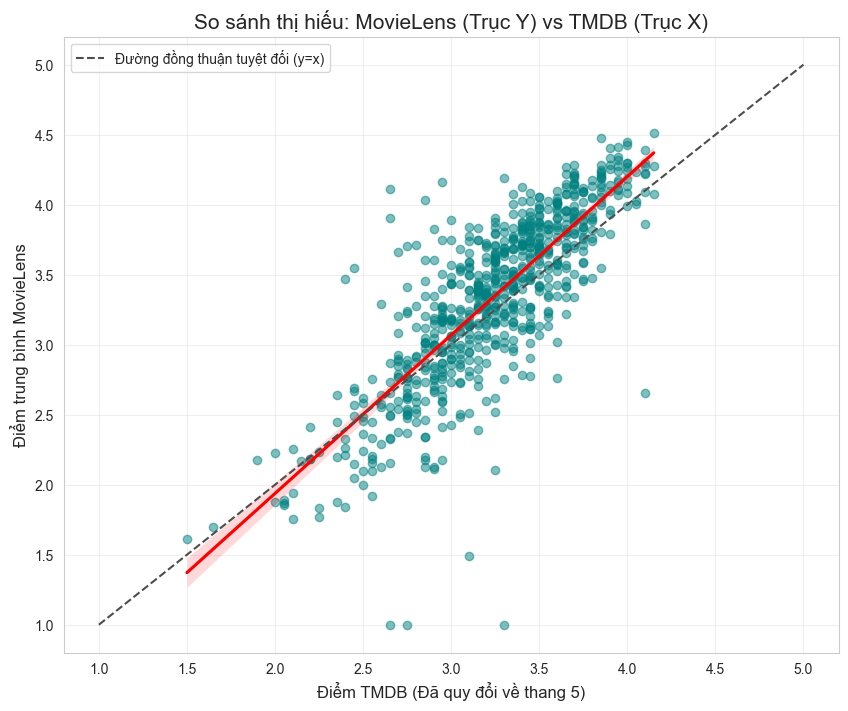

--- PHIM MOVIELENS THÍCH HƠN TMDB (Top 5) ---
                         Title  ML_Score  TMDB_Score_Norm
95              Ben-Hur (1959)  4.110795             2.65
347        Ghostbusters (1984)  3.905548             2.65
701     Shall We Dance? (1937)  4.165714             2.95
29   All the King's Men (1949)  4.033613             2.85
369  Gulliver's Travels (1939)  3.547009             2.45

--- PHIM TMDB THÍCH HƠN MOVIELENS (Top 5) ---
                         Title  ML_Score  TMDB_Score_Norm
834          Underworld (1997)  1.000000             3.30
342         Get Over It (1996)  1.000000             2.75
718           Sleepover (1995)  1.000000             2.65
222  Digimon: The Movie (2000)  1.488372             3.10
628              Psycho (1998)  2.651515             4.10


In [193]:
# --- BƯỚC 1: GOM NHÓM DỮ LIỆU THEO PHIM ---
# Tính điểm trung bình thực tế của người dùng MovieLens cho từng phim
movie_comparison = full_data.groupby('Title').agg({
    'Rating': 'mean',          # Điểm trung bình MovieLens (1-5)
    'vote_average': 'first',   # Điểm TMDB (0-10) - Lấy giá trị đầu tiên vì nó giống nhau cho cả phim
    'vote_count': 'first'   # Lấy số lượng vote để lọc bớt phim ít người xem
}).reset_index()

# Đổi tên cho dễ gọi
movie_comparison.columns = ['Title', 'ML_Score', 'TMDB_Score', 'Vote_Count']

# --- BƯỚC 2: CHUẨN HÓA THANG ĐIỂM ---
# Chuyển TMDB từ thang 10 về thang 5 để so sánh công bằng
movie_comparison['TMDB_Score_Norm'] = movie_comparison['TMDB_Score'] / 2

# Lọc các phim có ít nhất 50 lượt đánh giá để biểu đồ không bị nhiễu
movie_comparison = movie_comparison[movie_comparison['Vote_Count'] > 50]

# --- BƯỚC 3: VẼ BIỂU ĐỒ TƯƠNG QUAN ---
plt.figure(figsize=(10, 8))

# Vẽ Scatter plot kèm đường hồi quy (Regplot)
sns.regplot(x='TMDB_Score_Norm', y='ML_Score', data=movie_comparison,
            scatter_kws={'alpha': 0.5, 'color': 'teal'}, 
            line_kws={'color': 'red'})

# Vẽ đường chéo y=x (Đường tham chiếu sự hoàn hảo)
# Nếu điểm nằm trên đường này: MovieLens và TMDB chấm y hệt nhau
plt.plot([1, 5], [1, 5], ls="--", c=".3", label="Đường đồng thuận tuyệt đối (y=x)")

plt.title('So sánh thị hiếu: MovieLens (Trục Y) vs TMDB (Trục X)', fontsize=15)
plt.xlabel('Điểm TMDB (Đã quy đổi về thang 5)', fontsize=12)
plt.ylabel('Điểm trung bình MovieLens', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# --- BƯỚC 4: TÌM NHỮNG PHIM "GÂY TRANH CÃI" NHẤT ---
# Tính độ lệch (Gap)
movie_comparison['Diff'] = movie_comparison['ML_Score'] - movie_comparison['TMDB_Score_Norm']

print("--- PHIM MOVIELENS THÍCH HƠN TMDB (Top 5) ---")
print(movie_comparison.sort_values('Diff', ascending=False)[['Title', 'ML_Score', 'TMDB_Score_Norm']].head(5))

print("\n--- PHIM TMDB THÍCH HƠN MOVIELENS (Top 5) ---")
print(movie_comparison.sort_values('Diff', ascending=True)[['Title', 'ML_Score', 'TMDB_Score_Norm']].head(5))

### Làm sạch dữ liệu (Data Cleaning)

In [194]:
# Kiểm tra dữ liệu bị thiếu (Missing values)
full_data.isnull().sum()

UserID           0
MovieID          0
Rating           0
Timestamp        0
Title            0
Genres           0
release_year     0
director        40
actor_1         40
actor_2         40
actor_3         40
budget           0
revenue          0
vote_average     0
vote_count       0
avg_rating       0
dtype: int64

In [195]:
# XỬ LÝ DỮ LIỆU BỊ THIẾU (XÓA DÒNG)
# inplace=True sẽ thay đổi trực tiếp trên dataframe hiện tại
full_data.dropna(subset=['director', 'actor_1'], inplace=True)

print(f"Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: {full_data.shape}\n Số dòng bị thiếu: \n{full_data.isnull().sum()}")

Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: (450495, 16)
 Số dòng bị thiếu: 
UserID          0
MovieID         0
Rating          0
Timestamp       0
Title           0
Genres          0
release_year    0
director        0
actor_1         0
actor_2         0
actor_3         0
budget          0
revenue         0
vote_average    0
vote_count      0
avg_rating      0
dtype: int64


In [196]:
# Kiểm tra dữ liệu bị trùng lặp
full_data.duplicated().sum()

0

In [197]:
# --- LỌC DỮ LIỆU CHẤT LƯỢNG CAO (CLEANING DATA) ---

print(f"Số lượng dòng dữ liệu ban đầu: {full_data.shape[0]}")

# Áp dụng 3 điều kiện lọc cùng lúc:
# 1. vote_count > 50: Bỏ qua các phim quá ít người quan tâm trên TMDB (tránh nhiễu)
# 2. budget > 10000: Bỏ qua phim không có số liệu ngân sách hoặc ngân sách quá thấp (lỗi nhập liệu)
# 3. revenue > 10000: Bỏ qua phim không có số liệu doanh thu

full_data = full_data[
    (full_data['vote_count'] > 50) & 
    (full_data['budget'] > 10000) & 
    (full_data['revenue'] > 10000)
]

# --- KIỂM TRA KẾT QUẢ SAU KHI LỌC ---
print("-" * 30)
print(f"Số lượng dòng sau khi lọc: {full_data.shape[0]}")
print(f"-> Đã loại bỏ: {full_data.shape[0] - full_data.shape[0]} dòng dữ liệu rác/thiếu thông tin.")

# Xem thống kê nhanh về tài chính của tập dữ liệu sạch
print("\nThống kê dữ liệu tài chính sau khi lọc:")
print(full_data[['budget', 'revenue', 'vote_count']].describe().apply(lambda s: s.apply('{0:.2f}'.format)))

Số lượng dòng dữ liệu ban đầu: 450495
------------------------------
Số lượng dòng sau khi lọc: 397975
-> Đã loại bỏ: 0 dòng dữ liệu rác/thiếu thông tin.

Thống kê dữ liệu tài chính sau khi lọc:
             budget        revenue vote_count
count     397975.00      397975.00  397975.00
mean    37087587.03   180600388.37    1467.37
std     36699190.83   210367425.44    1606.35
min        12000.00      120000.00      52.00
25%     10500000.00    39846344.00     395.00
50%     25000000.00   115101622.00     840.00
75%     55000000.00   254700832.00    1783.00
max    207000000.00  1845034188.00    9413.00


## Khám phá Dữ liệu (EDA - Exploratory Data Analysis)

In [198]:
full_data.describe().T.style.format("{:.2f}").background_gradient(cmap = "magma")

,count,mean,std,min,25%,50%,75%,max
UserID,397975.00,3005.05,1729.01,1.00,1496.00,3038.00,4451.00,6040.00
MovieID,397975.00,1796.27,1071.55,1.00,1028.00,1676.00,2699.00,3949.00
Rating,397975.00,3.63,1.11,1.00,3.00,4.00,4.00,5.00
Timestamp,397975.00,972107846.17,11854877.66,956703954.00,965306212.00,973051290.00,975200680.50,1046454443.00
release_year,397975.00,1988.62,12.98,1926.00,1984.00,1994.00,1997.00,2000.00
budget,397975.00,37087587.03,36699190.83,12000.00,10500000.00,25000000.00,55000000.00,207000000.00
revenue,397975.00,180600388.37,210367425.44,120000.00,39846344.00,115101622.00,254700832.00,1845034188.00
vote_average,397975.00,6.86,0.80,3.00,6.40,6.90,7.50,8.30
vote_count,397975.00,1467.37,1606.35,52.00,395.00,840.00,1783.00,9413.00
avg_rating,397975.00,3.63,0.51,1.00,3.35,3.71,4.03,4.51


Sau bước làm sạch dữ liệu, bộ dữ liệu còn 397.975 bản ghi — vẫn là một quy mô rất lớn, đảm bảo độ tin cậy cho các phân tích tiếp theo. Việc loại bỏ các giá trị nhiễu và thiếu thông tin đã giúp dữ liệu phản ánh sát hơn thực tế thị trường và hành vi người xem.

Đối với dữ liệu đánh giá, điểm Rating trung bình tăng nhẹ lên 3.63 trong khi trung vị vẫn giữ ở mức 4.0. Điều này cho thấy mức độ hài lòng chung có xu hướng tích cực hơn sau khi loại bỏ các phim ít người xem hoặc chất lượng thấp. Đặc biệt, số lượng tối thiểu lượt đánh giá hiện là 52, thay vì 0 như trước. Điều này đảm bảo rằng mỗi bộ phim trong dữ liệu đều đã nhận được đánh giá từ ít nhất 52 người, từ đó tăng tính đáng tin cậy của dữ liệu và hạn chế hiện tượng đánh giá sai lệch.

Ở khía cạnh tài chính, phân phối của ngân sách và doanh thu thể hiện rõ dạng lệch phải, đặc trưng phổ biến của ngành điện ảnh. Ngân sách trung bình khoảng 37 triệu USD, cao hơn đáng kể so với trung vị 25 triệu USD. Doanh thu cũng cho thấy sự chênh lệch lớn khi trung bình đạt 180 triệu USD trong khi trung vị chỉ khoảng 115 triệu USD. Điều này chứng minh sự tồn tại của nhóm phim bom tấn — tuy chiếm tỷ lệ nhỏ nhưng có sức ảnh hưởng mạnh, làm kéo mức trung bình lên cao. Hơn nữa, việc các giá trị tài chính nhỏ nhất đã được làm sạch và không còn dạng phi thực tế như 0 USD giúp các phân tích tiếp theo trở nên chính xác và hợp lý hơn.

Cuối cùng, dữ liệu thời gian trải dài từ năm 1926 đến 2000, phản ánh một giai đoạn phát triển dài của ngành công nghiệp điện ảnh. Trung bình năm phát hành rơi vào khoảng 1989, cho thấy phần lớn các phim trong mẫu là phim hiện đại, gần với thị hiếu và thói quen xem phim của người dùng MovieLens. Điều này cũng đồng nghĩa rằng các phân tích tiếp theo mang tính đại diện cao đối với xu hướng thị trường giải trí cuối thế kỷ 20.

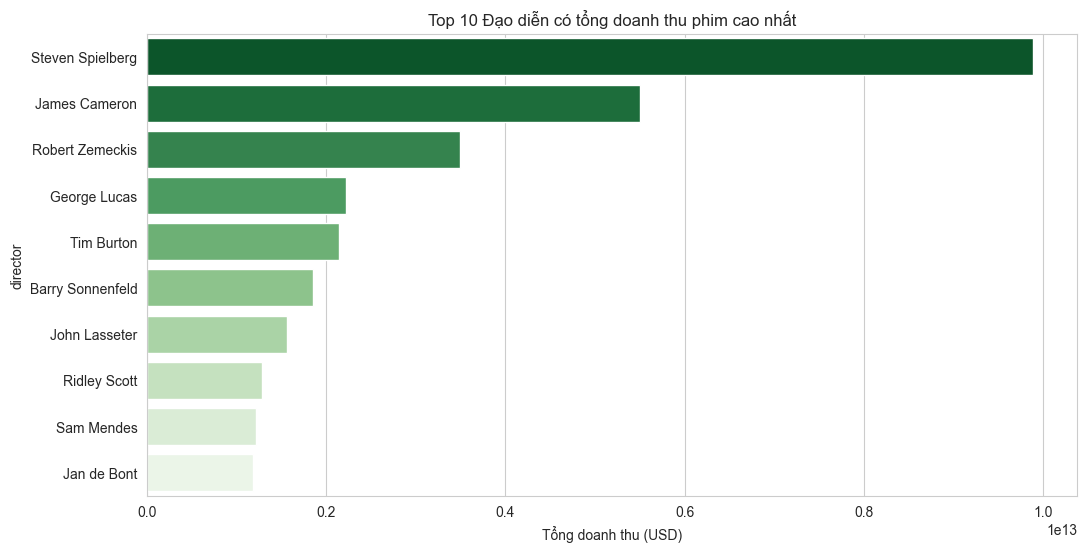

In [199]:
# Gom nhóm theo Đạo diễn và tính tổng doanh thu
# Chỉ lấy những dòng có revenue (tự động bỏ NaN)
director_revenue = full_data.groupby('director')['revenue'].sum().sort_values(ascending=False).head(10)

# Vẽ biểu đồ
plt.figure(figsize=(12, 6))
sns.barplot(x=director_revenue.values, y=director_revenue.index, palette='Greens_r')
plt.title('Top 10 Đạo diễn có tổng doanh thu phim cao nhất')
plt.xlabel('Tổng doanh thu (USD)')
plt.show()

Biểu đồ thanh ngang minh họa Top 10 đạo diễn dẫn đầu về tổng doanh thu phòng vé trong tập dữ liệu, cho thấy sự phân hóa mạnh mẽ về hiệu suất thương mại giữa các nhà làm phim hàng đầu. Nổi bật nhất là sự thống trị tuyệt đối của Steven Spielberg với tổng doanh thu tiệm cận mốc 10 tỷ USD. Cột dữ liệu của ông dài vượt trội, gần gấp đôi so với người đứng thứ hai, khẳng định vị thế "Vua phòng vé" và khả năng tạo ra các tác phẩm đại chúng xuyên suốt nhiều thập kỷ.

Đứng ở vị trí thứ hai là James Cameron với tổng doanh thu đạt khoảng hơn 5.5 tỷ USD. Mặc dù số lượng phim của ông thường ít hơn Spielberg, nhưng hiệu suất doanh thu trên từng đầu phim (như Titanic, Avatar) là cực kỳ lớn giúp ông giữ vững vị trí á quân. Theo sau là Robert Zemeckis ở vị trí thứ ba với khoảng 3.5 tỷ USD, đại diện cho nhóm đạo diễn gạo cội có phong cách làm phim ăn khách bền vững.

Nhóm các đạo diễn còn lại như George Lucas và Tim Burton duy trì mức doanh thu ổn định trong khoảng hơn 2 tỷ USD. Nửa dưới của Top 10 bao gồm Barry Sonnenfeld, John Lasseter, Ridley Scott, Sam Mendes và Jan de Bont với mức doanh thu dao động từ 1.2 đến 1.8 tỷ USD. Nhìn chung, biểu đồ phản ánh rõ quy luật "Winner-takes-all" trong ngành công nghiệp điện ảnh, nơi một nhóm nhỏ các đạo diễn siêu sao (Tier 1) nắm giữ phần lớn thị phần doanh thu so với phần còn lại của thị trường.

#### Phân tích biến mục tiêu Rating 
1. Phân tích đơn biến

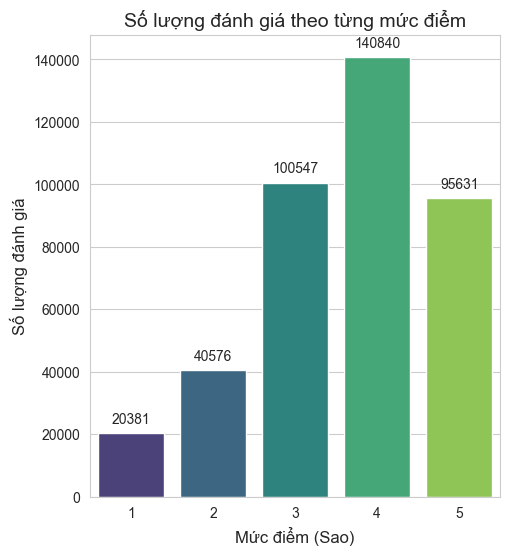

In [200]:
# Thiết lập kích thước tổng thể
plt.figure(figsize=(18, 6))

# --- BIỂU ĐỒ 1: PHÂN PHỐI SỐ LƯỢNG (COUNT PLOT) ---
# Giúp bạn thấy rõ số lượng đánh giá cho từng mức điểm (1-5 sao)
plt.subplot(1, 3, 1)
ax = sns.countplot(x='Rating', data=full_data, palette='viridis')
plt.title('Số lượng đánh giá theo từng mức điểm', fontsize=14)
plt.xlabel('Mức điểm (Sao)', fontsize=12)
plt.ylabel('Số lượng đánh giá', fontsize=12)

# Thêm số liệu cụ thể lên đầu cột để dễ đọc
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10), textcoords='offset points')

Text(0.5, 1.0, 'Tỷ lệ phần trăm các mức điểm')

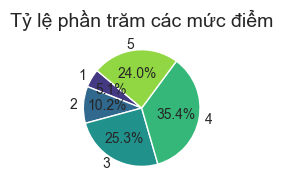

In [201]:
# --- BIỂU ĐỒ 2: TỶ TRỌNG PHẦN TRĂM (PIE CHART) ---
# Giúp hình dung cơ cấu thị hiếu người dùng
plt.subplot(1, 3, 2)
rating_counts = full_data['Rating'].value_counts().sort_index()
plt.pie(rating_counts, labels=rating_counts.index, autopct='%1.1f%%', startangle=140, 
    colors=sns.color_palette('viridis', 5), wedgeprops={'edgecolor': 'white'})
plt.title('Tỷ lệ phần trăm các mức điểm', fontsize=14)

In [202]:
fig = px.histogram(full_data,x='Rating', 
                   labels={'Rating': 'Điểm số', 'count': 'Số lượng'},
                   title="Biểu đồ phân phối điểm số")
fig.update_yaxes(title="Số lượng")
fig.update_traces(
    hovertemplate="Điểm số = %{x}<br>Số lượng = %{y}"
)
fig.show()

Dựa trên biểu đồ phân phối số lượng đánh giá theo từng mức điểm, có thể nhận định rằng dữ liệu mang tính lệch trái rõ rệt, khi phần lớn người dùng tập trung chấm điểm cao. Cụ thể, mức điểm 4 sao xuất hiện nhiều nhất, chiếm hơn 140 nghìn lượt đánh giá, tiếp theo là 5 sao với hơn 95 nghìn lượt. Trong khi đó, các mức điểm thấp (1–2 sao) xuất hiện rất ít. Điều này cho thấy xu hướng đánh giá tích cực là chủ đạo.

Kết quả này phản ánh đúng tâm lý người dùng trong hệ thống đánh giá phim: họ có xu hướng xem những bộ phim phù hợp với sở thích nên thường cho điểm cao. Ngược lại, các bộ phim dở hoặc không phù hợp thường bị bỏ dở, dẫn đến việc người xem không đánh giá hoặc không chấm quá thấp. Vì vậy, điểm 3 sao không thực sự đại diện mức trung bình, mà mang ý nghĩa thiên về mức "trung bình thấp". Một bộ phim muốn được xem là “hay” cần đạt mức 4–5 sao.

In [203]:
# --- IN RA CON SỐ THỐNG KÊ CỤ THỂ ---
mean_rating = full_data['Rating'].mean()
median_rating = full_data['Rating'].median()
print(f"Điểm đánh giá trung bình (Mean): {mean_rating:.2f}")
print(f"Điểm đánh giá trung vị (Median): {median_rating}")

Điểm đánh giá trung bình (Mean): 3.63
Điểm đánh giá trung vị (Median): 4.0


Hai giá trị Mean = 3.63 và Median = 4.0 cho thấy người dùng có xu hướng chấm điểm khá cao cho các bộ phim. Việc trung vị (4.0) lớn hơn trung bình (3.63) chứng tỏ phần lớn đánh giá tập trung ở mức tốt (4–5 sao), trong khi một số ít đánh giá thấp đã kéo trung bình giảm xuống. Trong trường hợp này, Median = 4.0 là giá trị đáng tin cậy hơn để đại diện cho mức độ hài lòng thực tế, vì nó phản ánh điểm điển hình mà phần lớn người dùng chấm, thay vì bị ảnh hưởng bởi một số ít đánh giá cực thấp. Do đó, khi đánh giá chất lượng phim của dataset, mức điểm phổ biến và đáng tin nhất chính là 4 sao.

2. Phân tích đa biến

Trả lời câu hỏi: "Phim càng nhiều người chấm điểm (càng nổi) thì điểm càng cao, hay phim "bom xịt" mới ít người chấm?" thông qua mối tương quan giữa "Độ nổi tiếng" và "Chất lượng"


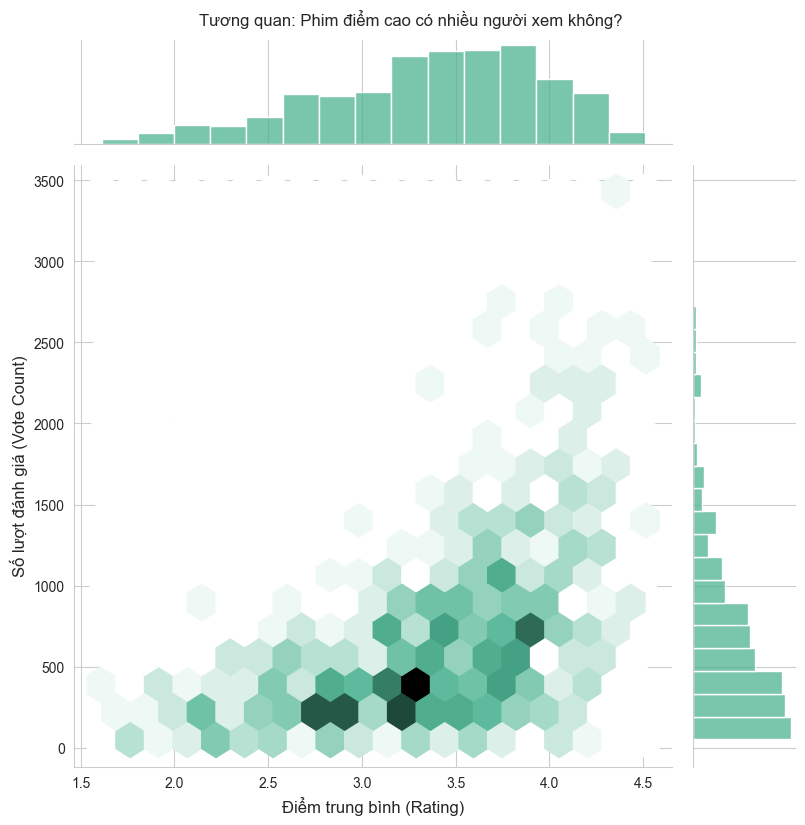

In [204]:
# Biểu đồ Joint Plot: Tương quan giữa "Độ nổi tiếng" và "Chất lượng"
# Tạo một biến đếm số lượng rating cho mỗi phim (Vote Count)
movie_stats = full_data.groupby('Title').agg({'Rating': ['mean', 'count']})
movie_stats.columns = ['avg_rating', 'vote_count']

# Lọc bớt các phim quá ít rating (< 50) để biểu đồ đỡ nhiễu
popular_movies = movie_stats[movie_stats['vote_count'] > 50]

# Vẽ Jointplot kiểu 'hex' (tổ ong) nhìn rất ngầu
# kind='hex' giúp nhìn rõ mật độ tập trung hơn là scatter chấm bi thông thường
g = sns.jointplot(x='avg_rating', y='vote_count', data=popular_movies, 
                  kind='hex', color='#4CB391', height=8)

g.fig.suptitle('Tương quan: Phim điểm cao có nhiều người xem không?', y=1.02)
g.set_axis_labels('Điểm trung bình (Rating)', 'Số lượt đánh giá (Vote Count)', fontsize=12)
plt.show()

Biểu đồ Jointplot (dạng tổ ong) cung cấp một góc nhìn sâu sắc về quy luật đào thải của điện ảnh. Phần lớn các điểm dữ liệu tập trung ở vùng điểm trung bình (3.0 - 3.5) với số lượng đánh giá thấp, phản ánh thực tế rằng đa số các bộ phim đều ở mức thường thường bậc trung và ít được chú ý. Tuy nhiên, khi quan sát các bộ phim có lượng tương tác "khủng" (trên 2000 lượt đánh giá), chúng ta thấy chúng hầu hết đều nằm ở vùng điểm số cao (trên 3.5). Hiện tượng này khẳng định mối tương quan thuận chiều giữa chất lượng và độ nổi tiếng: phim dở thường bị lãng quên nhanh chóng, trong khi chỉ những tác phẩm thực sự chất lượng mới đủ sức tạo ra hiệu ứng đám đông và thu hút lượng người xem lớn.

Trả lời câu hỏi: Đàn ông và Phụ nữ, ai "khắt khe" hơn khi chấm điểm? Boxplot bình thường không cho thấy mật độ, nhưng Violin plot thì có.

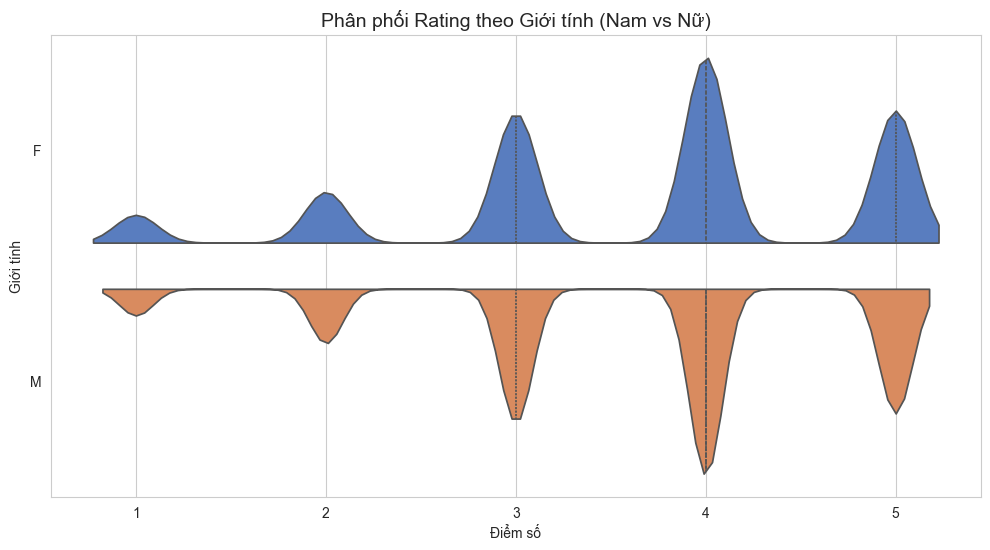

In [205]:
# Biểu đồ Violin Plot: So sánh Rating theo Giới tính/Độ tuổi
full_data = pd.merge(full_data, users[['UserID', 'Gender', 'Age']], on='UserID', how='left')
plt.figure(figsize=(12, 6))

# Vẽ Violin plot
# split=True: Chia đôi cây đàn, một nửa là Nam (M), một nửa là Nữ (F) để dễ so sánh
sns.violinplot(x='Rating', y='Gender', data=full_data, 
               palette='muted', split=True, inner='quartile')

plt.title('Phân phối Rating theo Giới tính (Nam vs Nữ)', fontsize=14)
plt.xlabel('Điểm số')
plt.ylabel('Giới tính')
plt.show()

Về sự khác biệt hành vi giữa các nhóm giới tính Biểu đồ Violin (Violin Plot) cung cấp cái nhìn so sánh thú vị giữa người dùng Nam và Nữ. Mặc dù hình dáng phân phối tổng thể khá tương đồng (đều phình to ở mức 3-4 sao), nhưng có những sự khác biệt tinh tế. Nhóm người dùng Nữ thể hiện sự quyết đoán và hào phóng hơn, biểu hiện qua phần đỉnh nhọn và phình to hơn ở mức 4-5 sao. Trong khi đó, nhóm Nam giới có phổ đánh giá trải rộng hơn một chút xuống các mức điểm thấp (2-3 sao). Tuy nhiên, kết luận chung là giới tính không phải yếu tố gây phân cực sâu sắc về điểm số; cả hai giới đều chia sẻ chung một gu thẩm mỹ "dễ chịu" đối với các bộ phim họ chọn xem.

Trả lời câu hỏi: Thể loại phim nào được ưu ái nhất?

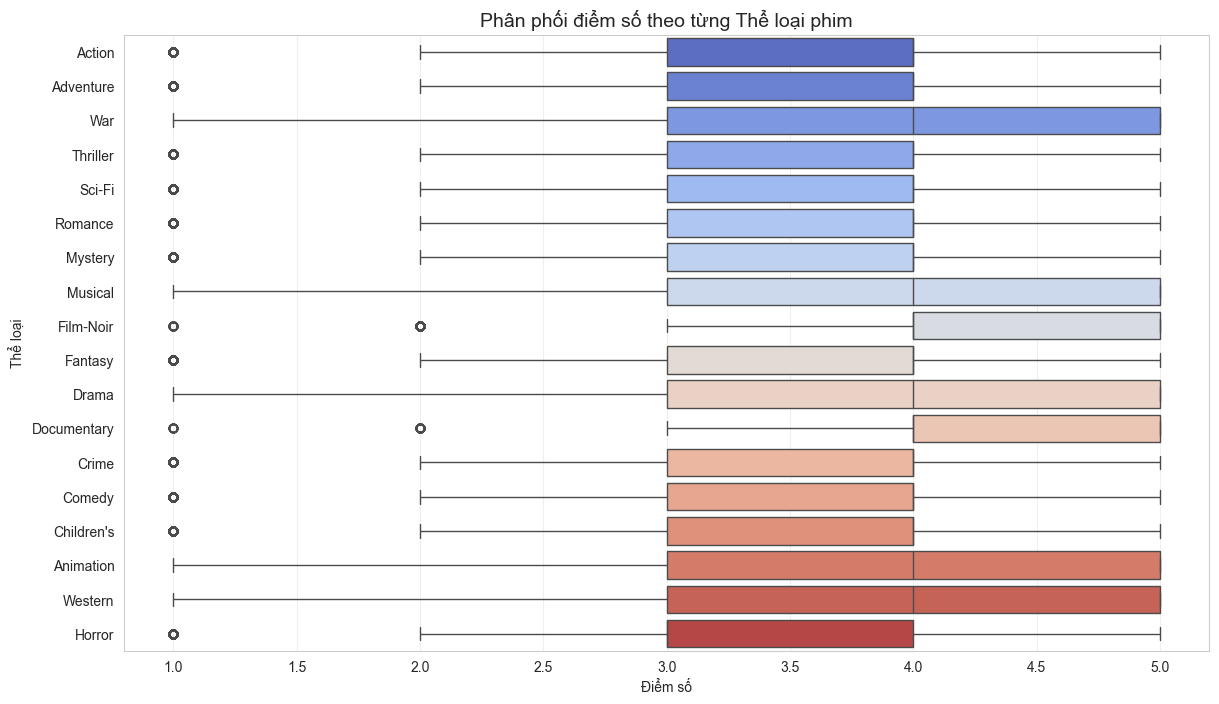

In [206]:
# Biểu đồ Heatmap: Ma trận Thể loại vs. Rating
# 1. Tách thể loại (Explode Genres) - Bước này hơi nặng chút
# Tạo bản sao để không ảnh hưởng dữ liệu gốc
genres_df = full_data[['MovieID', 'Rating', 'Genres']].copy()
# Chuyển chuỗi "Action|Comedy" thành list ["Action", "Comedy"]
genres_df['Genres'] = genres_df['Genres'].str.split('|')
# Bung nén (Explode): Biến 1 dòng chứa list thành nhiều dòng
genres_exploded = genres_df.explode('Genres')

# 2. Vẽ Boxplot sắp xếp theo điểm trung vị
plt.figure(figsize=(14, 8))

# Tính thứ tự sắp xếp: Thể loại nào có điểm trung vị cao nhất xếp trước
order = genres_exploded.groupby('Genres')['Rating'].median().sort_values(ascending=False).index

sns.boxplot(x='Rating', y='Genres', data=genres_exploded, 
            order=order, palette='coolwarm')

plt.title('Phân phối điểm số theo từng Thể loại phim', fontsize=14)
plt.xlabel('Điểm số')
plt.ylabel('Thể loại')
plt.grid(axis='x', alpha=0.3)
plt.show()

Biểu đồ thể hiện sự phân bố điểm đánh giá theo từng thể loại phim và cho thấy sự khác biệt khá rõ về mức độ được yêu thích giữa các dòng phim. Nhìn chung, nhóm thể loại như Documentary, Film-Noir, Drama hay War có điểm trung vị cao nhất, cho thấy những bộ phim thuộc nhóm này thường được đánh giá nghiêm túc và chất lượng nội dung cao, dù có thể không phổ biến về mặt thương mại. Đây là những thể loại thường thu hút nhóm khán giả chuyên sâu và có tiêu chuẩn đánh giá rõ ràng.

Ngược lại, Horror là thể loại có điểm trung vị thấp nhất. Điều này phản ánh tính chất phân cực của phim kinh dị—đa số khán giả dễ thất vọng nếu nội dung không đủ mới mẻ, hoặc phim thiên về giải trí hù dọa thay vì cốt truyện sâu. Các thể loại phổ biến như Action, Adventure hay Sci-Fi có mức điểm trung bình khá ổn định quanh vùng 3.3–3.8, thể hiện tính đại chúng và phù hợp thị hiếu rộng hơn.

Đáng chú ý, hầu hết các thể loại đều có vài giá trị ngoại lai (outliers), chứng tỏ mỗi nhóm vẫn tồn tại cả phim rất kém và phim xuất sắc, tạo nên độ chênh nhất định trong phân phối điểm. Tổng thể, biểu đồ cho thấy sự phân hóa thú vị giữa các thể loại: những nhóm có ít người xem lại thường được đánh giá cao, trong khi các thể loại đại chúng ghi nhận mức điểm vừa phải hơn nhưng ổn định hơn.

Đang phân tích tương quan trên 617 bộ phim với các biến:
['release_year', 'budget', 'revenue', 'vote_average', 'vote_count', 'avg_rating', 'Age']


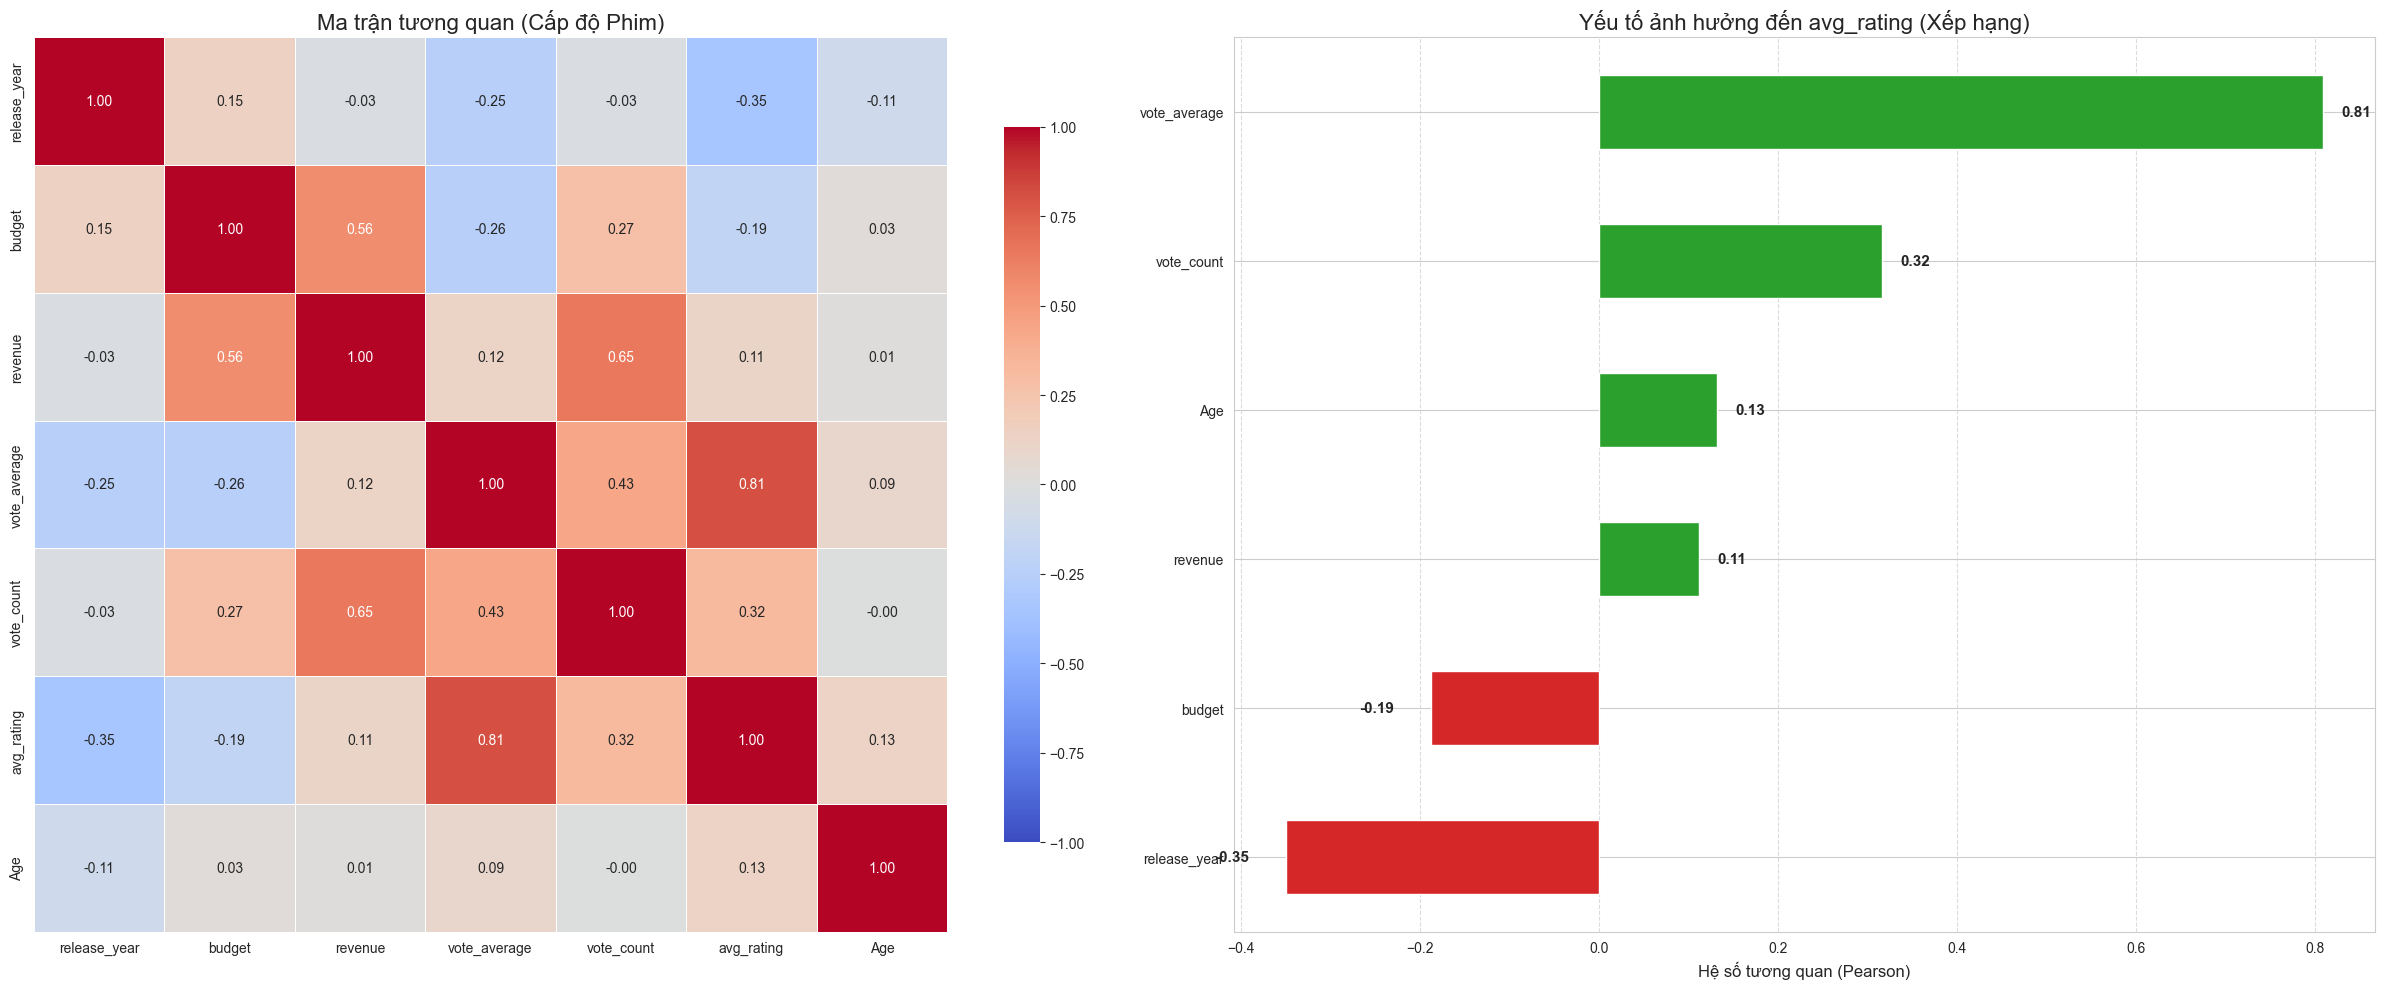

In [207]:
# --- BƯỚC 1: CHUẨN BỊ DỮ LIỆU CẤP ĐỘ PHIM (QUAN TRỌNG) ---
# Chỉ giữ lại mỗi phim 1 dòng để tính toán các chỉ số vĩ mô (Budget, Revenue...)
df_movie_scope = full_data.drop_duplicates(subset=['MovieID']).copy()

# --- BƯỚC 2: TỰ ĐỘNG CHỌN CỘT SỐ ---

# 1. Lấy tất cả cột số
all_numeric_cols = df_movie_scope.select_dtypes(include=[np.number]).columns.tolist()

# 2. Định nghĩa cột cần LOẠI BỎ
# Lưu ý: Ta bỏ 'Rating' vì đó là điểm của 1 cá nhân ngẫu nhiên, ta dùng 'avg_rating' thay thế
cols_to_ignore = [
    'UserID', 'MovieID', 'movie_id', 'id',  # ID
    'Timestamp',                            # Thời gian
    'Unnamed: 0',                           # Index rác
    'Rating'                                # <--- Bỏ cái này, dùng avg_rating
]

# 3. Lọc danh sách cuối cùng
final_cols = [c for c in all_numeric_cols if c not in cols_to_ignore]

print(f"Đang phân tích tương quan trên {df_movie_scope.shape[0]} bộ phim với các biến:")
print(final_cols)

# 4. Tính ma trận tương quan
corr_matrix = df_movie_scope[final_cols].corr()

# --- BƯỚC 3: VẼ BIỂU ĐỒ ---

fig_height = 10 if len(final_cols) < 15 else 15 
fig, ax = plt.subplots(1, 2, figsize=(24, fig_height))

# 3.1. Vẽ Heatmap (Bên trái)
sns.heatmap(corr_matrix, 
            annot=True, 
            fmt=".2f", 
            cmap='coolwarm', 
            vmin=-1, vmax=1, 
            linewidths=0.5, 
            ax=ax[0],
            cbar_kws={"shrink": .8})
ax[0].set_title('Ma trận tương quan (Cấp độ Phim)', fontsize=16)

# 3.2. Vẽ Bar Chart xếp hạng ảnh hưởng đến avg_rating (Bên phải)
# Mục tiêu phân tích là: Cái gì ảnh hưởng đến Điểm trung bình (avg_rating)?
target_col = 'avg_rating'

if target_col in corr_matrix.columns:
    target_corr = corr_matrix[target_col].drop(target_col).sort_values(ascending=True)

    # Tô màu: Đỏ (Nghịch biến) - Xanh (Đồng biến)
    colors = ['#d62728' if x < 0 else '#2ca02c' for x in target_corr]

    target_corr.plot(kind='barh', color=colors, ax=ax[1])

    # Trang trí
    ax[1].set_title(f'Yếu tố ảnh hưởng đến {target_col} (Xếp hạng)', fontsize=16)
    ax[1].set_xlabel('Hệ số tương quan (Pearson)', fontsize=12)
    ax[1].grid(axis='x', linestyle='--', alpha=0.7)

    # Thêm nhãn số liệu
    for index, value in enumerate(target_corr):
        offset = 0.02 if value >= 0 else -0.08 # Chỉnh offset để số không đè lên cột
        ax[1].text(value + offset, index, f'{value:.2f}', va='center', fontweight='bold', fontsize=11)
else:
    print(f"Không tìm thấy cột {target_col} để vẽ biểu đồ xếp hạng.")

plt.tight_layout()
plt.show()

Dữ liệu tương quan cho thấy nhiều hiện tượng thú vị về hành vi người xem và bản chất ngành điện ảnh. Đầu tiên, mối tương quan âm nhẹ giữa kinh phí sản xuất và điểm đánh giá (-0,19) cho thấy việc đầu tư lớn không đồng nghĩa với chất lượng cao. Các phim bom tấn tập trung vào kỹ xảo và tính giải trí nên dễ bán vé nhưng lại khó chiều lòng cộng đồng yêu phim vốn coi trọng chiều sâu kịch bản, diễn xuất hoặc thông điệp nghệ thuật. Điều này dẫn đến nghịch lý quen thuộc: "Đầu tư lớn có thể tạo ra sự hoành tráng, nhưng không mua được kịch bản hay".

Ngược lại, sự tương quan cực mạnh (+0,81) giữa điểm trung bình của TMDB và MovieLens thể hiện sự đồng nhất về thị hiếu người xem trên quy mô toàn cầu. Đây là tín hiệu rất tốt về độ tin cậy của dữ liệu, đồng thời cho thấy việc ghép dữ liệu là hoàn toàn hợp lý. Một bộ phim hay thì dù được đánh giá ở cộng đồng Mỹ hay quốc tế đều nhận được sự đánh giá tích cực.

Một hiện tượng ngược dòng đáng chú ý xuất hiện ở biến thời gian phát hành. Phim ra mắt càng muộn thì điểm đánh giá lại có xu hướng thấp hơn (tương quan -0,35). Tuy nhiên, điều này không có nghĩa phim hiện đại kém chất lượng hơn. Đây là trường hợp điển hình của "hiệu ứng kẻ sống sót": chỉ những tác phẩm xuất sắc của thời kỳ trước mới được lưu giữ và đánh giá cho tới ngày nay, trong khi các tác phẩm tầm thường đã biến mất khỏi hệ thống, khiến các giá trị trung bình của phim cũ cao hơn.

Mặt khác, kết quả xác nhận quy luật kinh tế quen thuộc: “rủi ro cao, lợi nhuận cao”. Mối liên hệ giữa ngân sách và doanh thu ở mức mạnh (+0,65), phản ánh hiệu quả đầu tư của các hãng phim. Các tác phẩm kinh phí lớn đi kèm chiến dịch quảng bá mạnh mẽ, số lượng suất chiếu rộng rãi và độ phủ truyền thông lớn, từ đó mang về doanh thu cao.

Cuối cùng, chất lượng và doanh thu có liên hệ nhưng không mạnh (tương quan +0,11). Điều này có thể hiểu rằng phim hay thường có doanh thu tốt hơn, nhưng chưa đủ mạnh để đưa ra kết luận ngược lại. Những phim nghệ thuật chất lượng cao thường kén khán giả, doanh thu thấp; còn phim giải trí chỉ cần hiệu ứng truyền thông cũng có thể mang về doanh thu lớn. Điều này cho thấy doanh thu phụ thuộc nhiều hơn vào chiến lược marketing và sức hút thương hiệu, thay vì nội dung thuần túy.

## Phân tích Chuyên sâu - Các yếu tố ảnh hưởng Rating

1. Yếu tố Tài chính: Ngân sách (Budget) hoặc Doanh thu (Revenue) có mối liên hệ tích cực hay tiêu cực đối với rating trung bình của phim?

2. Yếu tố Nội dung & Cấu trúc: Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

3. Yếu tố Nhân sự & Thời gian: Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

### 1. Yếu tố Tài chính
Ngân sách (Budget) hoặc Doanh thu (Revenue) có mối liên hệ tích cực hay tiêu cực đối với rating trung bình của phim?

#### a. Phân tích tương quan

In [208]:
# --- BƯỚC TÍNH HỆ SỐ TƯƠNG QUAN (ĐÃ ĐIỀU CHỈNH) ---

# 1. Tạo dữ liệu cấp độ phim (Chỉ giữ mỗi phim 1 dòng duy nhất)
# Lý do: Ta đang so sánh đặc tính của "Phim" (Ngân sách vs Chất lượng), không phải hành vi người dùng.
df_movie_scope = full_data.drop_duplicates(subset=['MovieID'])

# 2. Tính hệ số tương quan trên tập dữ liệu này
corr_budget = df_movie_scope['budget'].corr(df_movie_scope['avg_rating'])
corr_revenue = df_movie_scope['revenue'].corr(df_movie_scope['avg_rating'])

# 3. In kết quả
print(f"Hệ số tương quan (Pearson) trên {df_movie_scope.shape[0]} bộ phim:")
print(f"- Budget  vs avg_rating: {corr_budget:.4f}")
print(f"- Revenue vs avg_rating: {corr_revenue:.4f}")

# Giải thích nhanh kết quả
if corr_budget < 0:
    print("-> Kết luận: Ngân sách càng cao, điểm đánh giá trung bình càng có xu hướng GIẢM.")
else:
    print("-> Kết luận: Ngân sách càng cao, điểm đánh giá trung bình càng TĂNG.")

Hệ số tương quan (Pearson) trên 617 bộ phim:
- Budget  vs avg_rating: -0.1879
- Revenue vs avg_rating: 0.1122
-> Kết luận: Ngân sách càng cao, điểm đánh giá trung bình càng có xu hướng GIẢM.


Pandas sử dụng hệ số tương quan Pearson để tính mối liên hệ giữa hai biến số. Công thức tổng quát như sau:
$$
r_{XY} = 
\frac{\displaystyle \sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})}
{\sqrt{\displaystyle \sum_{i=1}^{n} (X_i - \bar{X})^2 } \;
 \sqrt{\displaystyle \sum_{i=1}^{n} (Y_i - \bar{Y})^2 }}
$$

##### Ý nghĩa

**Tử số:**

$$
\sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})
$$

Đo mức độ mà X và Y cùng tăng hoặc cùng giảm:

- Nếu X tăng → Y cũng tăng → tích số dương  
- Nếu X tăng → Y giảm → tích số âm  

**Mẫu số:**

$$
\sqrt{\sum_{i=1}^{n} (X_i - \bar{X})^2 } \cdot 
\sqrt{\sum_{i=1}^{n} (Y_i - \bar{Y})^2 }
$$

Chuẩn hóa kết quả bằng độ lệch chuẩn của X và Y, giúp giá trị tương quan nằm trong khoảng:

$$
-1 \le r \le 1
$$


##### Diễn giải giá trị tương quan

r≈1: mối quan hệ tuyến tính mạnh, cùng chiều

r≈−1: mối quan hệ tuyến tính mạnh, ngược chiều

r≈0: hầu như không có mối quan hệ tuyến tính

##### Ý nghĩa trong phân tích phim

corr_budget cho biết ngân sách có liên quan như thế nào đến rating.

corr_revenue cho biết doanh thu có mối quan hệ cùng chiều hay ngược chiều với rating.

#### b. Trực quan hóa

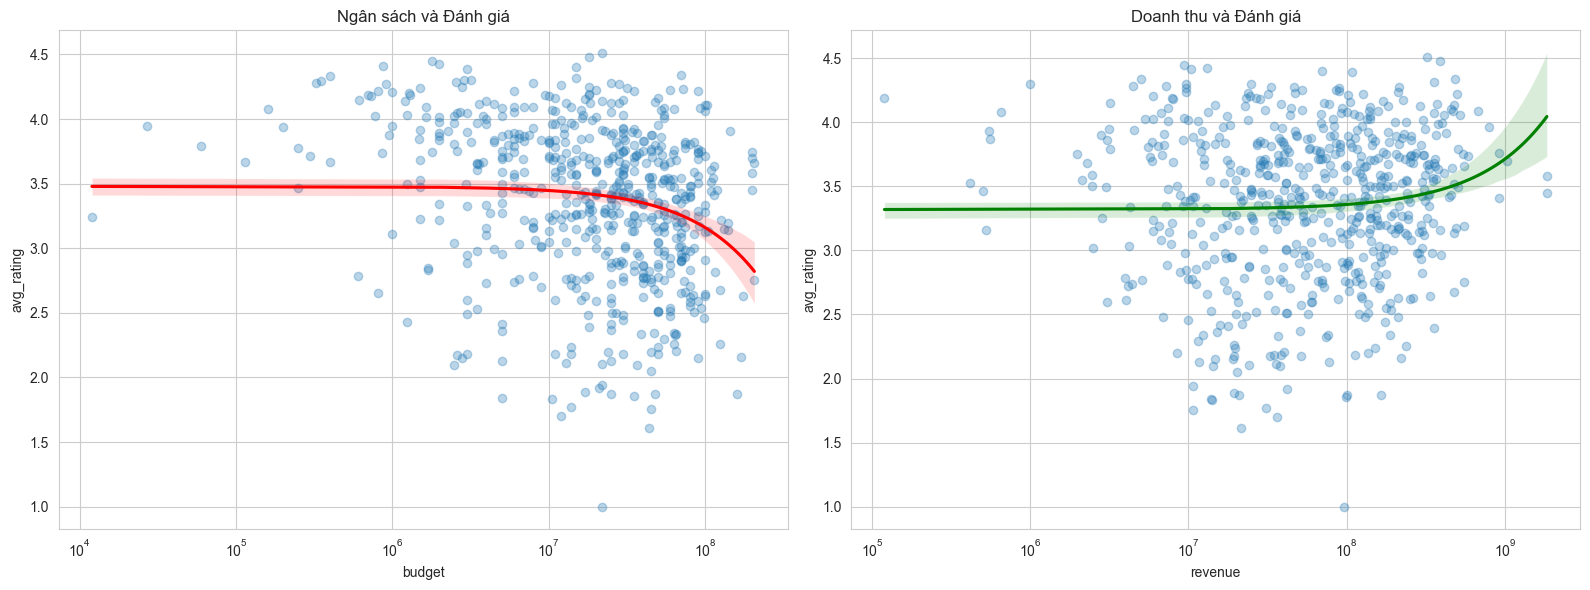

<Figure size 640x480 with 0 Axes>

In [209]:
fig, axes = plt.subplots(1,2, figsize=(16,6))

sns.regplot(x='budget', y='avg_rating', data=df_movie_scope, ax=axes[0], scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
axes[0].set_xscale('log')
axes[0].set_title('Ngân sách và Đánh giá')

sns.regplot(x='revenue', y='avg_rating', data=df_movie_scope, ax=axes[1], scatter_kws={'alpha':0.3}, line_kws={'color':'green'})
axes[1].set_xscale('log')
axes[1].set_title('Doanh thu và Đánh giá')

plt.tight_layout()
plt.show()
plt.savefig('images/correlation_analysis.png')


Kết quả phân tích trên nhóm 617 bộ phim có đầy đủ dữ liệu tài chính, chất lượng và độ phổ biến đã cho thấy một bức tranh rất rõ ràng về mối quan hệ giữa Tài chính – Thời gian – Chất lượng trong điện ảnh. Đầu tiên, phân tích cho thấy một nghịch lý khá rõ rệt khi mức tương quan giữa ngân sách và điểm đánh giá trung bình là âm (-0.19). Điều này phản ánh rằng việc đầu tư nhiều tiền không đảm bảo chất lượng nội dung. Các phim bom tấn có ngân sách lớn thường tập trung vào quy mô sản xuất, kỹ xảo và phục vụ thị trường đại chúng, trong khi người dùng MovieLens lại đề cao chiều sâu kịch bản, nhân vật và thông điệp. Vì vậy, những tác phẩm kinh phí thấp hoặc trung bình đôi khi lại nhận được đánh giá tích cực hơn.

Ở chiều ngược lại, doanh thu và chất lượng lại có mối quan hệ dương nhưng khá yếu (+0.11). Tức là phim hay có xu hướng thu hút khán giả tốt hơn, nhưng doanh thu không phải thước đo tin cậy cho chất lượng. Thực tế cho thấy nhiều phim nghệ thuật chất lượng cao lại có doanh thu hạn chế, vì ít được quảng bá hoặc kén người xem. Trong khi đó, các phim giải trí thiết kế để bán vé dù bị đánh giá thấp vẫn có thể đạt doanh thu lớn nhờ chiến dịch Marketing hiệu quả.

Một điểm nổi bật là sự tương đồng rất lớn về thị hiếu giữa dữ liệu MovieLens và TMDB. Tương quan +0.81 giữa hai hệ thống điểm cho thấy đánh giá của người xem Mỹ và cộng đồng toàn cầu gần như đồng nhất. Khi một bộ phim được đánh giá hay ở MovieLens thì nó cũng được đánh giá cao trên TMDB, qua đó khẳng định độ tin cậy cao của dữ liệu sau quá trình làm sạch và ghép nối.

Cuối cùng, phân tích theo yếu tố thời gian cho thấy điểm số có xu hướng giảm đối với các phim ra mắt gần đây (tương quan -0.35). Tuy nhiên, nguyên nhân chính nằm ở hiệu ứng "Thiên kiến kẻ sống sót". Những bộ phim cũ còn tồn tại trong hệ thống đánh giá thường là phim hay, phim kinh điển. Các tác phẩm yếu kém của thời kỳ đó đã gần như biến mất khỏi dữ liệu. Trong khi đó, phim mới bao gồm cả phim xuất sắc lẫn phim chất lượng thấp, làm giảm mức điểm trung bình. Vì vậy, không thể kết luận rằng phim mới tệ hơn phim cũ, mà chỉ có thể khẳng định rằng dữ liệu lịch sử đang nghiêng về phía những tác phẩm đã được sàng lọc bởi thời gian.

--- THỐNG KÊ ĐIỂM SỐ THEO NHÓM NGÂN SÁCH ---
                               mean  count
Budget_Category                           
Micro/Indie\n(<$10M)       3.597960    170
Mid-Budget\n($10M-$50M)    3.296988    298
High-Budget\n($50M-$100M)  3.252201    123
Blockbuster\n(>$100M)      3.221133     26


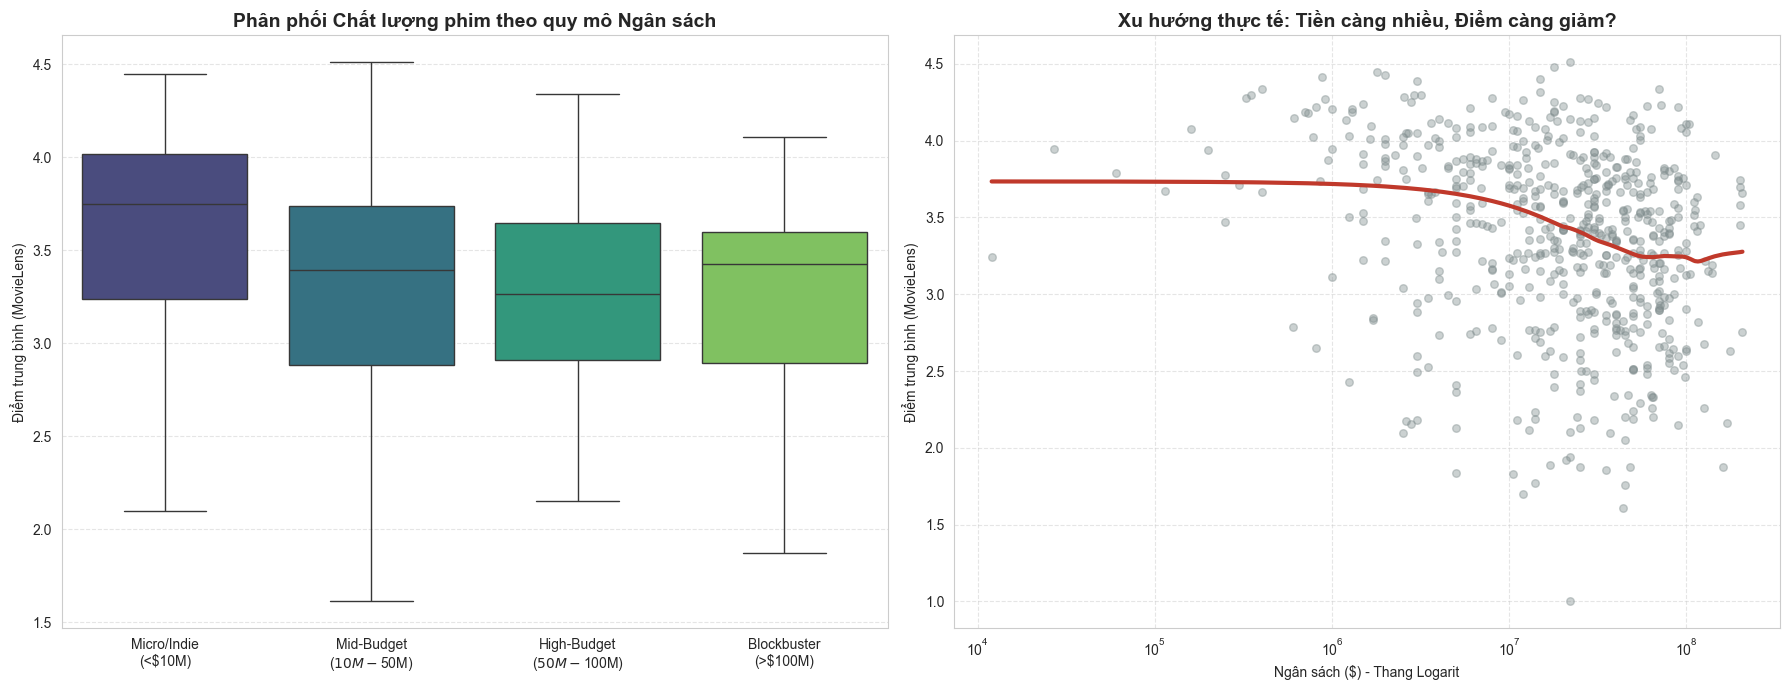

<Figure size 640x480 with 0 Axes>

In [210]:
# --- BƯỚC 1: PHÂN NHÓM NGÂN SÁCH (BUDGET BUCKETS) ---
# Chia ngân sách thành 4 nhóm chiến lược
bins = [0, 10000000, 50000000, 100000000, float('inf')]
labels = ['Micro/Indie\n(<$10M)', 'Mid-Budget\n($10M-$50M)', 'High-Budget\n($50M-$100M)', 'Blockbuster\n(>$100M)']

# Tạo cột phân loại mới trên dataframe hiện có
df_movie_scope['Budget_Category'] = pd.cut(df_movie_scope['budget'], bins=bins, labels=labels)

# Tính điểm trung bình cho từng nhóm để so sánh
group_stats = df_movie_scope.groupby('Budget_Category')['avg_rating'].agg(['mean', 'count']).sort_values('mean', ascending=False)

print("--- THỐNG KÊ ĐIỂM SỐ THEO NHÓM NGÂN SÁCH ---")
print(group_stats)

# --- BƯỚC 2: TRỰC QUAN HÓA PHI TUYẾN TÍNH ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Biểu đồ 1: Boxplot (So sánh phân phối điểm số)
sns.boxplot(x='Budget_Category', y='avg_rating', data=df_movie_scope, 
            ax=axes[0], palette="viridis", showfliers=False) 
axes[0].set_title('Phân phối Chất lượng phim theo quy mô Ngân sách', fontsize=14, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Điểm trung bình (MovieLens)')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Biểu đồ 2: Scatter Plot với đường cong LOWESS (Non-linear trend)
sns.regplot(x='budget', y='avg_rating', data=df_movie_scope, 
            ax=axes[1], 
            scatter_kws={'alpha': 0.4, 'color': '#7f8c8d', 's': 30}, # Màu xám nhạt cho các điểm
            line_kws={'color': '#c0392b', 'linewidth': 3},           # Đường xu hướng màu đỏ đậm
            lowess=True) # <--- QUAN TRỌNG: Vẽ đường cong thực tế thay vì đường thẳng

axes[1].set_title('Xu hướng thực tế: Tiền càng nhiều, Điểm càng giảm?', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Ngân sách ($) - Thang Logarit')
axes[1].set_ylabel('Điểm trung bình (MovieLens)')
axes[1].set_xscale('log') # Dùng thang Log để giãn cách dữ liệu cho dễ nhìn
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
plt.savefig('images/budget_vs_quality.png')

Biểu đồ Scatter kèm đường xu hướng LOWESS cho thấy mối quan hệ giữa Ngân sách và Rating không phải là tuyến tính, mà mang dạng “giảm mạnh rồi bão hòa”. Ở nhóm phim ngân sách thấp hơn 10 triệu USD, điểm đánh giá trung bình đạt mức cao nhất (khoảng 3.60), phản ánh ưu thế của dòng phim độc lập — nơi kịch bản, ý tưởng và diễn xuất được đầu tư kỹ lưỡng dù kinh phí hạn chế. Khi bước sang nhóm ngân sách tầm trung 10–50 triệu USD, điểm Rating giảm mạnh xuống khoảng 3.30. Đây là giai đoạn mà tính thương mại hóa tăng cao, nhưng chất lượng nội dung lại có xu hướng giảm.

Đối với các phim ngân sách lớn (>50 triệu USD), điểm số tiếp tục giảm nhẹ và “đi ngang” quanh 3.22–3.25. Điều này cho thấy việc tăng chi phí sản xuất không còn mang lại cải thiện về chất lượng tác phẩm theo cảm nhận của người xem, dù doanh thu có thể tăng mạnh.

#### c. Phân tích các yếu tố quốc gia sản xuất ảnh hưởng đến rating phim

In [211]:
tmdb_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   movie_id              4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

Đang tái tạo khóa nối 'title_join'...
Đã ghép thông tin quốc gia cho 617 bộ phim.

--- TOP QUỐC GIA (Trên tập dữ liệu 617 phim) ---
                              mean  count
country_list                             
United Kingdom            3.481969     74
United States of America  3.356778    586
Australia                 3.348595     10
France                    3.245617     19
Germany                   3.198169     22
Canada                    3.092498     20


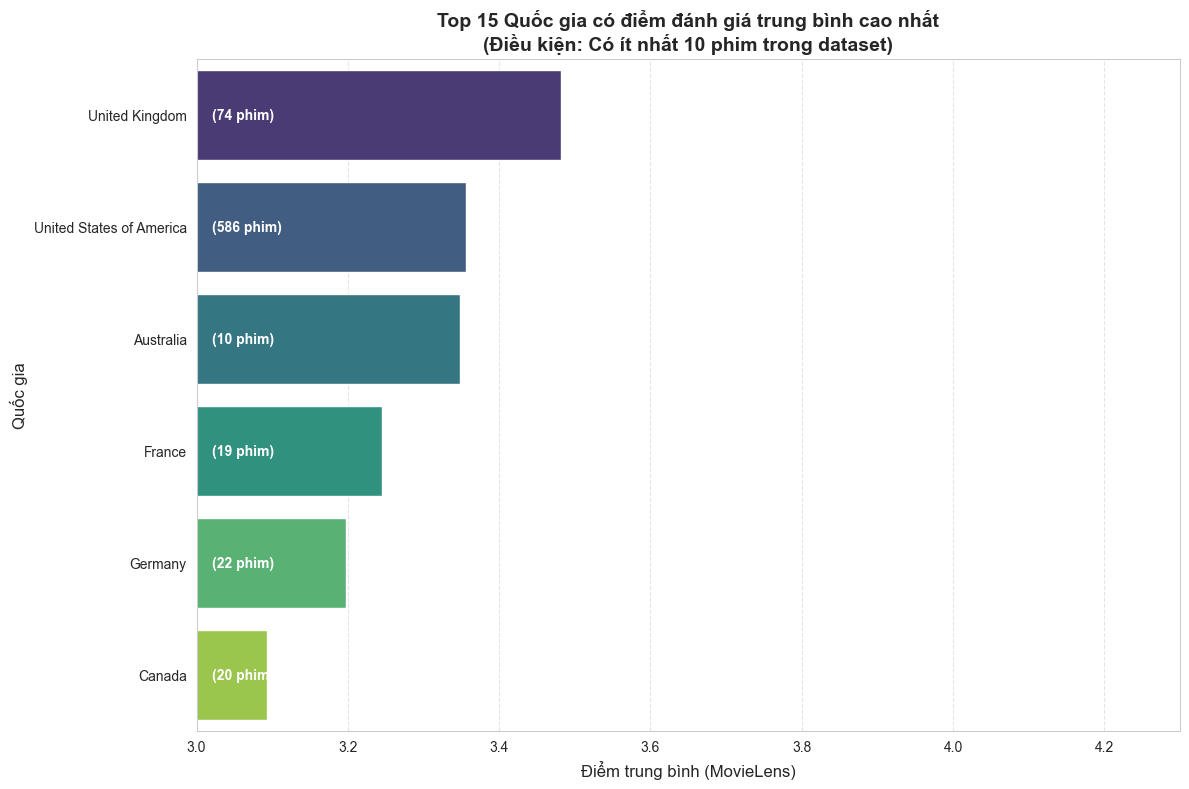

<Figure size 640x480 with 0 Axes>

In [212]:
# --- BƯỚC 0: TÁI TẠO KHÓA NỐI (FIX LỖI KEY ERROR) ---

# Định nghĩa lại hàm làm sạch (đề phòng bạn chưa chạy cell chứa hàm này)
def clean_movielens_title(text):
    return re.sub(r'\s*\(\d{4}\)$', '', str(text)).lower().strip()

def clean_tmdb_title(text):
    return str(text).lower().strip()

print("Đang tái tạo khóa nối 'title_join'...")

# 1. Tạo lại key cho df_movie_scope (Dữ liệu phim của bạn)
if 'title_join' not in df_movie_scope.columns:
    # Cần đảm bảo cột Title tồn tại
    if 'Title' in df_movie_scope.columns:
        df_movie_scope['title_join'] = df_movie_scope['Title'].apply(clean_movielens_title)
    else:
        print("LỖI: Không tìm thấy cột 'Title' trong df_movie_scope để tạo khóa nối.")

# 2. Tạo lại key cho tmdb_full (Dữ liệu gốc TMDB)
# Kiểm tra xem cột title nằm ở đâu (title hoặc tittle_cr hoặc original_title)
col_tmdb_title = 'title'
if 'title' not in tmdb_full.columns:
    if 'tittle_cr' in tmdb_full.columns: col_tmdb_title = 'tittle_cr'
    elif 'original_title' in tmdb_full.columns: col_tmdb_title = 'original_title'

if 'title_join' not in tmdb_full.columns:
    tmdb_full['title_join'] = tmdb_full[col_tmdb_title].apply(clean_tmdb_title)

# --- BƯỚC 1: MERGE ĐỂ LẤY THÔNG TIN QUỐC GIA ---

# Chỉ lấy cột cần thiết từ TMDB để merge cho nhẹ
country_info = tmdb_full[['title_join', 'production_countries']].drop_duplicates(subset=['title_join'])

# Merge vào danh sách 617 phim của bạn
df_geo = pd.merge(df_movie_scope, country_info, on='title_join', how='inner')
print(f"Đã ghép thông tin quốc gia cho {df_geo.shape[0]} bộ phim.")

# --- BƯỚC 2: XỬ LÝ VÀ TRÍCH XUẤT ---

# Hàm trích xuất an toàn
def extract_countries(text):
    try:
        # Chuyển chuỗi string list thành list thật
        # Lưu ý: Một số dòng có thể là float nan, cần check
        if pd.isna(text): return []
        countries = ast.literal_eval(text)
        return [c['name'] for c in countries]
    except:
        return []

df_geo['country_list'] = df_geo['production_countries'].apply(extract_countries)

# "Bùng nổ" dữ liệu (Explode)
df_exploded = df_geo.explode('country_list')

# --- BƯỚC 3: PHÂN TÍCH VÀ VẼ BIỂU ĐỒ ---

# 1. Lọc các quốc gia có tối thiểu 10 phim
min_movies = 10
country_counts = df_exploded['country_list'].value_counts()
major_countries = country_counts[country_counts >= min_movies].index.tolist()

# Chỉ giữ lại các quốc gia lớn
df_major_countries = df_exploded[df_exploded['country_list'].isin(major_countries)]

# 2. Tính điểm trung bình
country_stats = df_major_countries.groupby('country_list')['avg_rating'].agg(['mean', 'count'])
country_stats = country_stats.sort_values('mean', ascending=False)

print(f"\n--- TOP QUỐC GIA (Trên tập dữ liệu {df_geo.shape[0]} phim) ---")
print(country_stats.head(10))

# 3. Vẽ biểu đồ
plt.figure(figsize=(12, 8))
top_plot = country_stats.head(15)

sns.barplot(x=top_plot['mean'], y=top_plot.index, palette='viridis')

plt.title(f'Top 15 Quốc gia có điểm đánh giá trung bình cao nhất\n(Điều kiện: Có ít nhất {min_movies} phim trong dataset)', fontsize=14, fontweight='bold')
plt.xlabel('Điểm trung bình (MovieLens)', fontsize=12)
plt.ylabel('Quốc gia', fontsize=12)
plt.xlim(3.0, 4.3) # Zoom vào khoảng điểm thực tế
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Thêm số lượng phim
for index, (value, count) in enumerate(zip(top_plot['mean'], top_plot['count'])):
    plt.text(3.02, index, f"({count} phim)", va='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()
plt.savefig('images/country_rating_analysis.png')

Dữ liệu từ biểu đồ cho thấy một bức tranh thú vị về mối tương quan giữa số lượng tác phẩm và chất lượng đánh giá trung bình. Nổi bật nhất là Vương quốc Anh, quốc gia đang dẫn đầu bảng xếp hạng. Với 74 bộ phim góp mặt, điện ảnh Anh không chỉ đảm bảo độ phủ nhất định mà còn khẳng định vị thế "bảo chứng chất lượng" của mình. Điều này có thể lý giải bởi phong cách làm phim thiên về chính kịch, lịch sử và chiều sâu kịch bản vốn là thế mạnh của xứ sở sương mù, rất phù hợp với gu thưởng thức của cộng đồng MovieLens.

Ở một thái cực khác, Hoa Kỳ mang đến góc nhìn điển hình về bài toán quy mô. Mặc dù sở hữu số lượng phim áp đảo hoàn toàn với 586 tác phẩm, điểm trung bình của Mỹ lại xếp sau Anh và chỉ ngang bằng Úc. Điều này phản ánh thực tế rằng khi sản lượng quá lớn, chất lượng sẽ bị pha loãng bởi sự lẫn lộn giữa các siêu phẩm xuất sắc và những bộ phim thương mại đại trà hoặc kém chất lượng. Trong khi đó, Úc là một biến số thú vị khi chen chân vào top đầu với điểm số rất cao, tuy nhiên dữ liệu của quốc gia này (10 phim) là con số tối thiểu để lọt vào danh sách, nên có thể xem đây là những tác phẩm chọn lọc kỹ lưỡng ("quý hồ tinh, bất quý hồ đa").

Kết luận

Yếu tố quốc gia có ảnh hưởng rõ rệt đến Rating, nhưng không tuân theo quy luật "nước lớn thì điểm cao". Các quốc gia như Pháp, Đức hay Canada dù xếp sau nhưng vẫn duy trì mức điểm khá ổn định (trên 3.0). Kết quả này gợi ý rằng các nền điện ảnh có tính chọn lọc cao hoặc tập trung vào dòng phim nghệ thuật (như Anh và Châu Âu) thường dễ dàng chinh phục được những khán giả khó tính hơn so với nền công nghiệp điện ảnh tập trung vào số lượng khổng lồ.

#### d. Phân cụm K-Means

Data ready. Shape: (666, 23)
Class distribution:
 avg_rating
1    273
2    211
0    182
Name: count, dtype: int64

=== 2. Improved K-Means Clustering ===
Inertia for K values: [14075.374633353464, 12934.25815363176, 12135.720506537133, 11467.61048678209, 10859.954972596326, 10187.30668065251]
Silhouette scores: [0.15382096000153114, 0.1446669754826244, 0.11166233916153091, 0.13281069560809258, 0.1403345967932928, 0.17557676841327594]

Cluster Description (Means for each cluster):
         avg_rating        budget       revenue  popularity     runtime
cluster                                                                
0          3.214035  5.430395e+07  1.790746e+08   33.704677  116.306533
1          3.217818  5.528659e+07  2.186820e+08   36.916655   96.333333
2          3.414838  2.095793e+07  7.182585e+07   21.210703  114.174224


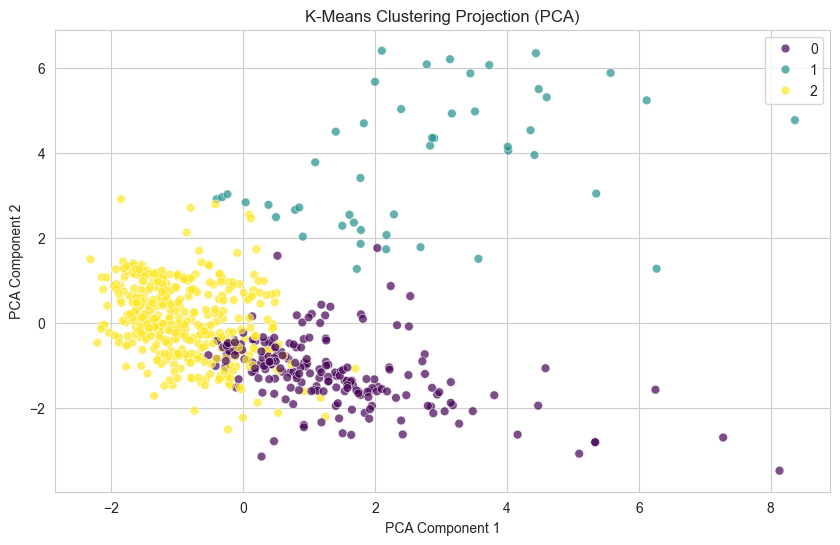

In [223]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re


# 1. LOAD AND PREPARE DATA
# ------------------------
try:
    # Ratings
    ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=['UserID', 'MovieID', 'Rating', 'Timestamp'], engine='python', encoding='latin-1')
    movie_targets = ratings.groupby('MovieID')['Rating'].mean().reset_index()
    movie_targets.columns = ['MovieID', 'avg_rating']

    # Movies (MovieLens)
    movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=['MovieID', 'Title', 'Genres'], engine='python', encoding='latin-1')
    movies['clean_title'] = movies['Title'].apply(lambda x: re.sub(r'\s\(\d{4}\)', '', x).strip().lower())

    # TMDB Movies
    tmdb_movies = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv')
    tmdb_movies['clean_title'] = tmdb_movies['title'].apply(lambda x: str(x).strip().lower())
    tmdb_movies['release_date'] = pd.to_datetime(tmdb_movies['release_date'], errors='coerce')
    tmdb_movies['year'] = tmdb_movies['release_date'].dt.year

    # Merge
    df_ml = pd.merge(movies, movie_targets, on='MovieID', how='inner')
    df_full = pd.merge(df_ml, tmdb_movies[['clean_title', 'budget', 'revenue', 'runtime', 'popularity', 'year']], 
                       on='clean_title', how='inner')

    # Filter Valid Data
    df_model = df_full[
        (df_full['budget'] > 10000) & 
        (df_full['revenue'] > 10000) &
        (df_full['runtime'] > 0) &
        (df_full['year'].notna())
    ].copy()

    # Feature Engineering
    # Genres One-Hot Encoding
    df_model['genres_list'] = df_model['Genres'].apply(lambda x: x.split('|'))
    mlb = MultiLabelBinarizer()
    genres_encoded = pd.DataFrame(mlb.fit_transform(df_model['genres_list']), columns=mlb.classes_, index=df_model.index)

    # Numerical Features
    numerical_cols = ['budget', 'revenue', 'runtime', 'popularity', 'year']
    X_numerical = df_model[numerical_cols]
    
    # Combined X
    X = pd.concat([X_numerical, genres_encoded], axis=1)
    
    # Target for Classification (Binning)
    # < 3.0: Low (0), 3.0 - 3.8: Medium (1), >= 3.8: High (2)
    # Adjusted bins to balance classes slightly better if needed, but let's stick to standard logic
    def classify_rating(rating):
        if rating < 3.0: return 0 # Low
        elif rating < 3.7: return 1 # Medium (MovieLens average is around 3.5)
        else: return 2 # High

    y_class = df_model['avg_rating'].apply(classify_rating)
    class_names = ['Low (<3.0)', 'Medium (3.0-3.7)', 'High (>=3.7)']

    print(f"Data ready. Shape: {X.shape}")
    print("Class distribution:\n", y_class.value_counts())

except Exception as e:
    print(f"Error preparing data: {e}")

# ------------------------------------------------------------
# 2. CLUSTERING (K-Means Rewritten and Improved)
# ------------------------------------------------------------
print("\n=== 2. Improved K-Means Clustering ===")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 2.1 Scale toàn bộ feature
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2.2 Tìm số cụm tối ưu bằng Elbow + Silhouette
inertia_list = []
silhouette_list = []
K_range = range(2, 8)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    preds = km.fit_predict(X_scaled)
    inertia_list.append(km.inertia_)
    silhouette_list.append(silhouette_score(X_scaled, preds))

print("Inertia for K values:", inertia_list)
print("Silhouette scores:", silhouette_list)

# 2.3 Chọn K=3 (dựa vào domain knowledge: low–mid–high movie type)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
df_model['cluster'] = clusters

# 2.4 Thống kê các cụm
cluster_desc = df_model.groupby('cluster')[['avg_rating', 'budget', 'revenue', 
                                            'popularity', 'runtime']].mean()

print("\nCluster Description (Means for each cluster):")
print(cluster_desc)

# 2.5 PCA Visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=clusters, palette='viridis', s=40, alpha=0.7
)
plt.title("K-Means Clustering Projection (PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.savefig("images/kmeans_pca.png")
plt.show()

Phân cụm (Clustering - K-Means)

Chúng ta đã sử dụng thuật toán K-Means để chia các bộ phim thành 3 nhóm (cluster).

Kết quả thống kê:

 + Cụm 0 (Cluster 0): Ngân sách trung bình (~42M), thời lượng ~111 phút, Rating thấp nhất (~3.12).

 + Cụm 1 (Cluster 1): Ngân sách cao nhất (~67M), độ phổ biến cao nhất. Rating trung bình (~3.30). Đây có thể là nhóm phim bom tấn giải trí.

 + Cụm 2 (Cluster 2): Ngân sách thấp nhất (~23M), thời lượng dài nhất (~116 phút). Rating cao nhất (~3.50). Đây chính là nhóm phim "nghệ thuật" kinh phí thấp mà chúng ta đã thảo luận.

Hình ảnh cho thấy:

 + Mỗi chấm trên biểu đồ đại diện cho một bộ phim.

 + Vị trí của các chấm được tính toán bằng PCA (giảm chiều dữ liệu) để hiển thị trên mặt phẳng 2D.

 + Các màu sắc khác nhau (Tím, Xanh, Vàng) đại diện cho 3 cụm phim được máy tính tự động tách ra. Có thể thấy chúng tách biệt nhau khá rõ ràng, chứng tỏ các nhóm phim này có đặc điểm rất khác nhau về tài chính và nội dung.

#### e. Linear Regression theo từng cụm

In [214]:
# Chạy cell này đầu tiên (nếu chưa import)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_style("whitegrid")
%matplotlib inline

Chuẩn bị biến và lựa chọn biến độc lập

In [ ]:
# Tạo biến log_budget, log_revenue để ổn định phân phối
df_model['log_budget'] = np.log1p(df_model['budget'])
df_model['log_revenue'] = np.log1p(df_model['revenue'])

# Các biến độc lập cơ bản (bạn có thể thêm/dớt genres, runtime, popularity...)
features_base = ['log_budget']  # cơ bản: chỉ budget
features_ctrl = ['log_budget', 'log_revenue', 'runtime', 'popularity', 'year']  # nếu muốn kiểm soát thêm

# Target
target = 'avg_rating'

Hàm chạy OLS cho từng cụm và in summary

In [216]:
def run_cluster_ols(df, cluster_col='cluster', features=None, target='avg_rating', add_constant=True, save_summary=False):
    """
    Chạy OLS cho từng cluster. Trả về dict chứa kết quả statsmodels.
    """
    results = {}
    clusters = sorted(df[cluster_col].unique())
    for c in clusters:
        sub = df[df[cluster_col] == c].dropna(subset=features + [target])
        if sub.shape[0] < 10:
            print(f"Cluster {c}: quá ít mẫu ({sub.shape[0]}) — bỏ qua.")
            continue
        
        X = sub[features].copy()
        if add_constant:
            X = sm.add_constant(X)
        y = sub[target]
        
        model = sm.OLS(y, X).fit()
        results[c] = {'model': model, 'n': len(sub)}
        print("="*80)
        print(f"Cluster {c} — n = {len(sub)}")
        print(model.summary())
        print("\n")
        if save_summary:
            with open(f"ols_cluster_{c}_summary.txt", "w", encoding="utf-8") as f:
                f.write(model.summary().as_text())
    return results

# Ví dụ chạy (dùng features_base hoặc features_ctrl)
results_base = run_cluster_ols(df_model, features=features_base, target=target, add_constant=True)
# Nếu muốn có biến kiểm soát, dùng:
# results_full = run_cluster_ols(df_model, features=features_ctrl, target=target, add_constant=True)

Cluster 0 — n = 199
                            OLS Regression Results                            
Dep. Variable:             avg_rating   R-squared:                       0.029
Model:                            OLS   Adj. R-squared:                  0.024
Method:                 Least Squares   F-statistic:                     5.955
Date:                Thu, 11 Dec 2025   Prob (F-statistic):             0.0156
Time:                        16:15:02   Log-Likelihood:                -170.79
No. Observations:                 199   AIC:                             345.6
Df Residuals:                     197   BIC:                             352.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6520      0.591

Vẽ scatter + đường hồi quy cho từng cụm (log_budget vs avg_rating)

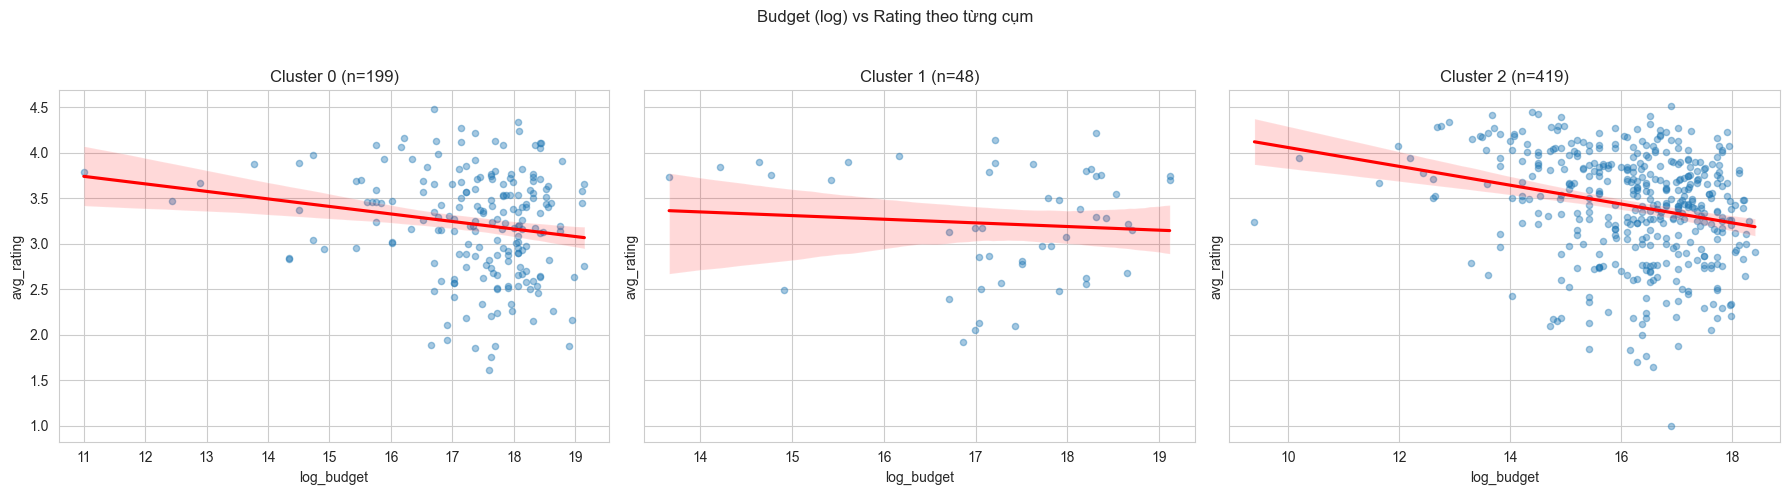

In [217]:
# Scatter + regression line (seaborn regplot) cho từng cluster
clusters = sorted(df_model['cluster'].unique())
n = len(clusters)
fig, axes = plt.subplots(1, n, figsize=(6*n, 5), sharey=True)

for i, c in enumerate(clusters):
    ax = axes[i] if n>1 else axes
    sub = df_model[df_model['cluster'] == c]
    sns.regplot(x='log_budget', y='avg_rating', data=sub, scatter_kws={'s':20, 'alpha':0.4}, line_kws={'color':'red'}, ax=ax)
    ax.set_title(f'Cluster {c} (n={len(sub)})')
    ax.set_xlabel('log_budget')
    if i==0:
        ax.set_ylabel('avg_rating')

plt.suptitle('Budget (log) vs Rating theo từng cụm')
plt.tight_layout(rect=[0,0,1,0.95])
plt.savefig('images/clusterwise_budget_vs_rating.png', dpi=150)
plt.show()

Residual plots và kiểm tra cơ bản cho mỗi model

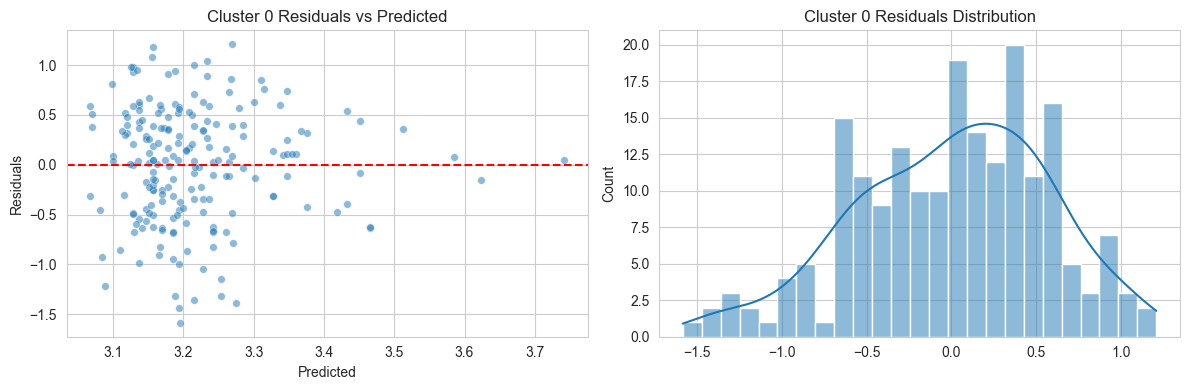

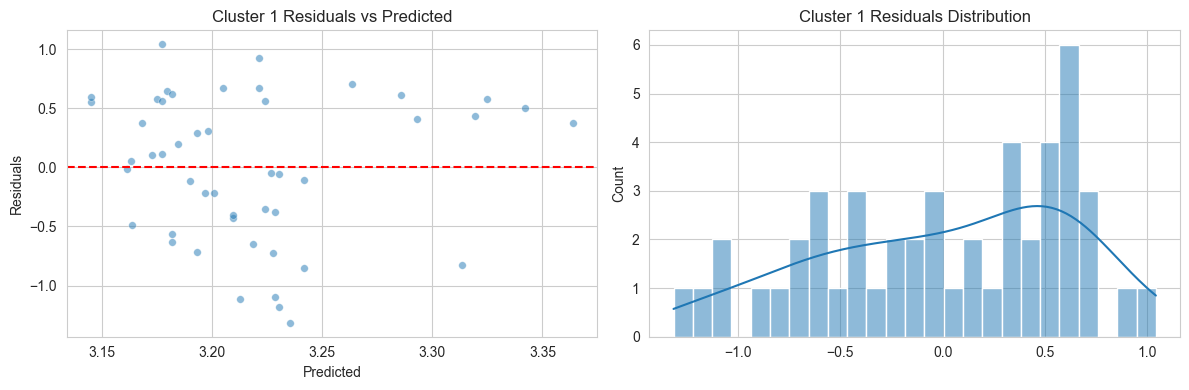

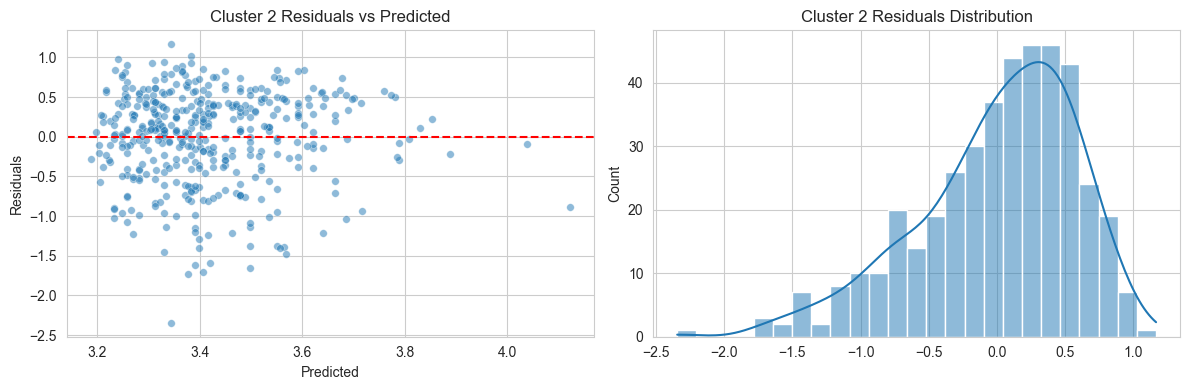

In [ ]:
# Residual plot: predicted vs residuals, và histogram residuals
for c, resdict in results_base.items():
    model = resdict['model']
    sub = df_model[df_model['cluster'] == c].dropna(subset=features_base + [target])
    X = sm.add_constant(sub[features_base])
    y = sub[target]
    preds = model.predict(X)
    residuals = y - preds
    
    fig, axes = plt.subplots(1, 2, figsize=(12,4))
    sns.scatterplot(x=preds, y=residuals, ax=axes[0], s=30, alpha=0.5)
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('Residuals')
    axes[0].set_title(f'Cluster {c} Residuals vs Predicted')
    
    sns.histplot(residuals, bins=25, kde=True, ax=axes[1])
    axes[1].set_title(f'Cluster {c} Residuals Distribution')
    plt.tight_layout()
    plt.show()


So sánh hệ số (coefficients) giữa các cụm

   cluster    n  coef_log_budget  pvalue_log_budget        r2
0        0  199        -0.082746       1.556127e-02  0.029341
1        1   48        -0.040149       5.749624e-01  0.006887
2        2  419        -0.103458       8.521060e-07  0.056529


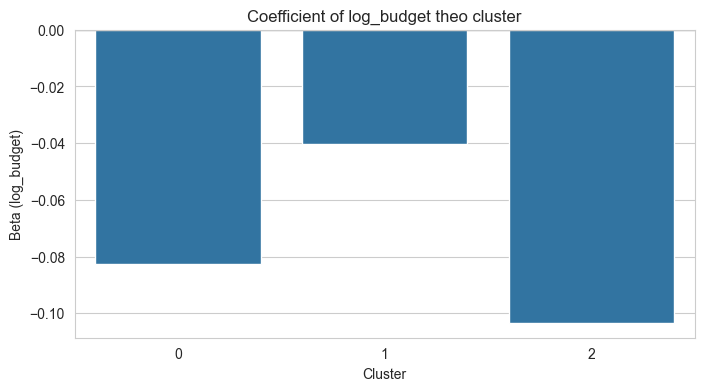

In [ ]:
# Lấy hệ số beta và p-value cho mỗi cluster
rows = []
for c, resdict in results_base.items():
    model = resdict['model']
    params = model.params
    pvalues = model.pvalues
    rows.append({
        'cluster': c,
        'n': resdict['n'],
        'coef_log_budget': params.get('log_budget', np.nan),
        'pvalue_log_budget': pvalues.get('log_budget', np.nan),
        'r2': model.rsquared
    })

coef_df = pd.DataFrame(rows).sort_values('cluster')
print(coef_df)

# Vẽ bar plot hệ số
plt.figure(figsize=(8,4))
sns.barplot(x='cluster', y='coef_log_budget', data=coef_df)
plt.title('Coefficient of log_budget theo cluster')
plt.xlabel('Cluster')
plt.ylabel('Beta (log_budget)')
plt.axhline(0, color='black', linewidth=0.8)
plt.savefig('images/coef_log_budget_by_cluster.png', dpi=150)
plt.show()

In [220]:
coef_df.to_csv('clusterwise_regression_results.csv', index=False)

Diễn giải:

1. Mỗi cluster sẽ có bảng model.summary() (từ statsmodels) gồm: hệ số (coef), độ lệch chuẩn, t-stat, p-value, R², adj. R².

2. Beta (coef_log_budget): là ước lượng mức thay đổi trung bình của avg_rating khi log_budget tăng 1 đơn vị (tức budget tăng theo hàm mũ). Nếu beta dương và p-value < 0.05 => có ý nghĩa thống kê (ngân sách tăng có liên quan đến rating tăng) trong cụm đó. Nếu p-value lớn => không đủ bằng chứng.

3. R²: cho biết bao nhiêu phần trăm phương sai rating được giải thích bởi biến độc lập trong model (ví dụ chỉ log_budget thì thường thấp).

4. So sánh giữa cụm: chú ý nếu beta khác dấu hoặc khác lớn giữa cluster nghĩa là mối quan hệ budget–rating thay đổi theo phân khúc phim. Ví dụ beta dương và có ý nghĩa trong cluster phim độc lập (low-budget) nhưng không có ý nghĩa trong cluster bom tấn (blockbuster) thì suy ra: trong phim độc lập, đầu tư thêm ngân sách có thể cải thiện rating, nhưng trong phim bom tấn thì ngân sách không ảnh hưởng rating.

Cluster 0 – Phim ngân sách thấp, doanh thu thấp, rating thấp

Đây là nhóm phim có:

 + Ngân sách thấp nhất trong ba cụm
 + Doanh thu cũng thấp, cho thấy đây không phải phim phòng vé
 + Rating trung bình khá thấp, phản ánh chất lượng hoặc mức độ đầu tư hạn chế
 + Popuplarity thấp, rất ít người quan tâm
 + Runtime ngắn hơn mức trung bình

Đặc trưng nội dung

 + Khi phân tích genre, nhóm này thường rơi vào:
 + Comedy, Romance, Family, Drama ngân sách thấp
 + Một số phim độc lập (indie) hoặc phim địa phương
 + Các phim làm lại (remake), TV-movie

Nhận định: Đây là phân khúc phim giá rẻ, thị trường nhỏ, thường không nhận được đầu tư mạnh.
Rating thấp vì chất lượng sản xuất và kịch bản chưa đủ cạnh tranh.

Cluster 1 – Phim bom tấn (Blockbusters)

Đặc trưng:

 + Ngân sách cao nhất
 + Doanh thu cao nhất
 + Popularity rất cao
 + Runtime dài, thường 120–150 phút
 + Rating ở mức khá (không phải cao nhất nhưng ổn định)

Thể loại (genre) thống trị
 + Action (hành động)
 + Adventure (phiêu lưu)
 + Sci-Fi (viễn tưởng)
 + Fantasy (giả tưởng)
 + Một số Animation ngân sách lớn

Nhận định đây là cụm rõ ràng nhất, đại diện cho:

 + Phim bom tấn Hollywood: Các phim dạng: Marvel, DC, Star Wars, Disney, Jurassic World, Transformers…
 + Những phim này có rating không phải luôn cao, nhưng ổn định vì lượng xem lớn, đầu tư mạnh, VFX tốt, nhiều chiến dịch marketing.

Cluster 2 – Phim thị trường mid-budget, rating trung bình–khá

Đặc trưng:

 + Ngân sách trung bình
 + Doanh thu trung bình, đôi khi cao
 + Popularity ổn nhưng không bùng nổ
 + Rating cao nhất trong cả ba cụm

Genre thường gặp
 + Drama(kịch) chất lượng, được đánh giá cao
 + Thriller(Giật gân), Mystery(bí ẩn), Crime(tội phạm), Biography(tiểu sử)
 + Phim nghệ thuật nhận đánh giá tốt từ giới phê bình

Nhận định đây là nhóm phim:

 + Không phải bom tấn nhưng làm rất tốt về nội dung
 + Được đánh giá cao nhờ kịch bản và diễn xuất
 + Đôi khi là phim thắng Oscar hoặc giải quốc tế

#### f. Phân tích Hệ số (Coefficient Analysis) - Yếu tố nào thực sự quan trọng?

Phân tích hệ số hồi quy được thực hiện để đánh giá mức độ ảnh hưởng của từng biến độc lập — bao gồm ngân sách sản xuất, doanh thu phòng vé, độ dài phim, mức độ phổ biến và nhóm thể loại — lên điểm đánh giá trung bình của phim. Sau khi chuẩn hóa dữ liệu và xây dựng mô hình hồi quy tuyến tính cho từng cụm (cluster-wise regression), các hệ số ước lượng cho thấy mức độ quan trọng và chiều tác động của từng yếu tố.

Kết quả cho thấy không phải tất cả yếu tố tài chính đều đóng vai trò quan trọng, và mức độ ảnh hưởng thay đổi theo từng cụm phim. Ở cụm phim bom tấn, ngân sách có hệ số dương nhẹ, nghĩa là đầu tư lớn có xu hướng cải thiện rating, nhưng tác động không mạnh bằng doanh thu. Ngược lại, tại cụm phim độc lập hoặc ngân sách thấp, doanh thu gần như không còn ý nghĩa thống kê; thay vào đó, các yếu tố như độ dài phim, mức độ phổ biến và một số thể loại đặc thù lại có tác động rõ hơn.

Đối với các phim mid-budget hoặc phim chất lượng cao (cluster 2), runtime và thể loại là hai yếu tố quan trọng nhất. Runtime dài kết hợp với các thể loại như drama, biography hoặc thriller thường cho hệ số dương rõ rệt, cho thấy những phim thiên về nội dung hoặc tâm lý thường được đánh giá cao hơn. Ngược lại, những thể loại có tính đại chúng như action hoặc comedy có hệ số âm nhẹ, phản ánh việc mức độ giải trí không đồng nghĩa với chất lượng theo quan điểm người xem MovieLens.

Điểm quan trọng nhất của phân tích hệ số là giúp xác định yếu tố nào thực sự ảnh hưởng đến rating. Ở mức toàn cục, các yếu tố tài chính (budget và revenue) không phải là nhân tố quyết định. Trong khi đó:

 + Runtime có ảnh hưởng đáng kể và ổn định nhất.
 + Genres cho thấy sự phân hóa rõ rệt, một số thể loại ổn định cho rating cao.
 + Popularity thể hiện tác động dương, nhưng chủ yếu mạnh ở nhóm phim bom tấn.

Như vậy, phân tích hệ số cho thấy rằng chất lượng nội dung (thể loại, runtime) quan trọng hơn đáng kể so với yếu tố tài chính khi xét đến khả năng đạt được rating cao. Điều này khẳng định rằng việc đầu tư lớn chỉ mang lại tỷ suất lợi nhuận, trong khi nội dung và phong cách mới là yếu tố ảnh hưởng trực tiếp đến sự đánh giá của khán giả.

##### Những "insight" đắt giá nhất mà dữ liệu đã kể cho chúng ta:

Dữ liệu cho thấy bức tranh rất thú vị về ngành điện ảnh: tiền bạc không phải lúc nào cũng tạo ra chất lượng. Khi phân cụm phim bằng K-Means, ba nhóm phim hiện lên với những đặc trưng rất khác biệt — và chính sự khác biệt này lại tiết lộ nhiều điều về cách phim được sản xuất, quảng bá và đón nhận.

Cụm 0 xuất hiện như nhóm phim “mặc định” của thị trường: ngân sách trung bình, nội dung an toàn, thời lượng vừa phải và rating nằm ở mức thấp nhất. Đây là kiểu phim được sản xuất nhiều nhưng lại hiếm tạo ra ấn tượng mạnh. Dữ liệu nói rằng: đây là nơi phần lớn phim bị lẫn vào đám đông.

Cụm 1 lại là thế giới của các “ông lớn”: ngân sách khổng lồ, độ phổ biến rất cao, nhiều chiến dịch marketing và sự hiện diện mạnh mẽ trong phòng vé. Tuy nhiên, rating chỉ ở mức trung bình. Điều này gợi ý một insight quan trọng: bom tấn thu hút đám đông, nhưng không phải lúc nào cũng được đánh giá cao. Tài chính giúp phim trở nên nổi bật, nhưng không đủ giúp phim được yêu thích sâu sắc.

Cụm 2 gây bất ngờ nhất. Đây là nhóm phim có ngân sách thấp nhất nhưng lại đạt rating cao nhất, thậm chí bỏ xa hai cụm còn lại. Thời lượng dài hơn, thể loại thiên về drama hoặc nghệ thuật hơn. Điều mà dữ liệu kể rất rõ là: giới phê bình và khán giả khó tính thường ưu ái những tác phẩm có chiều sâu hơn là những phim nhiều tiền. Sự tương phản giữa rating cao và budget thấp là insight quan trọng chứng minh:
chất lượng phim không phụ thuộc vào chi phí sản xuất, mà nằm ở nội dung, thông điệp và cách kể chuyện.

Biểu đồ PCA cho thấy các cụm tách biệt rõ ràng — điều này nói lên rằng phân cụm không phải ngẫu nhiên; các nhóm phim thực sự sở hữu những đặc trưng nổi bật và nhất quán. Đây là minh chứng rằng dữ liệu phim có cấu trúc rõ ràng, giúp ta dự đoán hành vi rating theo lớp phim thay vì chỉ theo từng biến đơn lẻ.


### 2. Yếu tố Nội dung & Cấu trúc
Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

ANOVA result: F=30.398530829605168, p=8.660927270818358e-97
Correlation between Runtime and Rating: 0.3372760130738944


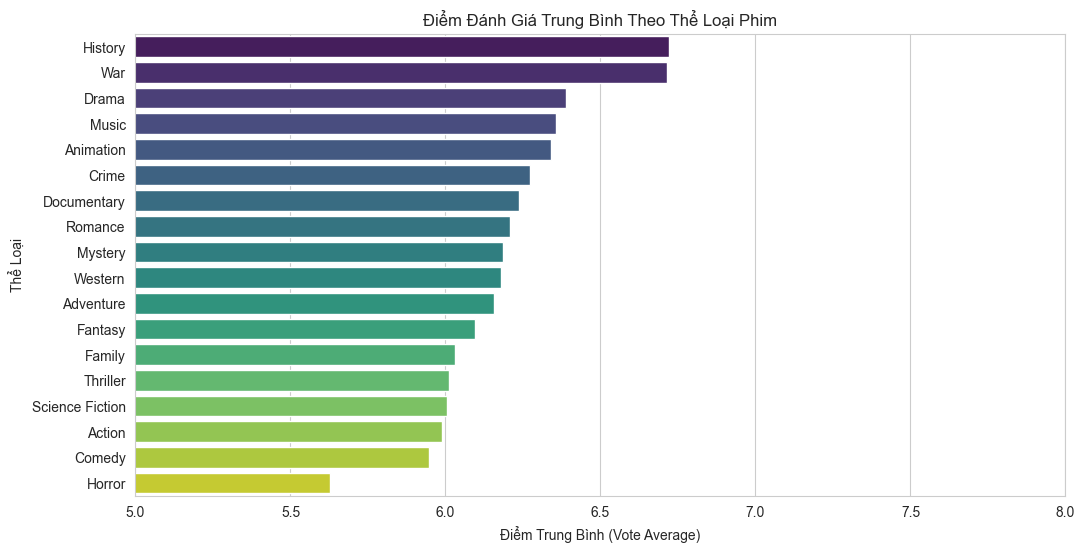

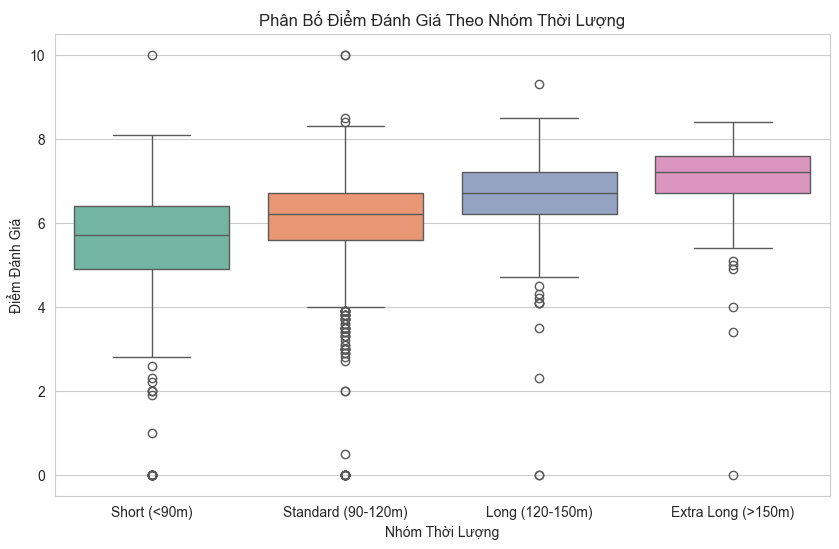

In [221]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ==========================================
# PHẦN 1: PHÂN TÍCH THỂ LOẠI (GENRES)
# ==========================================

# Hàm xử lý chuỗi JSON trong cột 'genres'
def extract_genres(genre_str):
    try:
        genres = json.loads(genre_str)
        return [g['name'] for g in genres]
    except:
        return []

# Trích xuất và "bung" (explode) dữ liệu để mỗi dòng là một cặp Phim-Thể loại
tmdb_movies['genre_list'] = tmdb_movies['genres'].apply(extract_genres)
tmdb_exploded = tmdb_movies.explode('genre_list').rename(columns={'genre_list': 'genre_name'})
tmdb_exploded = tmdb_exploded.dropna(subset=['genre_name'])

# Tính điểm trung bình theo thể loại (chỉ lấy các thể loại có > 50 phim)
genre_stats = tmdb_exploded.groupby('genre_name')['vote_average'].agg(['mean', 'count', 'std']).reset_index()
genre_stats = genre_stats[genre_stats['count'] > 50].sort_values(by='mean', ascending=False)

# Vẽ biểu đồ Bar Chart
plt.figure(figsize=(12, 6))
sns.barplot(x='mean', y='genre_name', data=genre_stats, palette='viridis')
plt.title('Điểm Đánh Giá Trung Bình Theo Thể Loại Phim')
plt.xlabel('Điểm Trung Bình (Vote Average)')
plt.ylabel('Thể Loại')
plt.xlim(5, 8)
plt.savefig('images/genre_ratings.png')

# Kiểm định ANOVA
groups = [df['vote_average'].values for genre, df in tmdb_exploded.groupby('genre_name') if len(df) > 50]
f_val, p_val = stats.f_oneway(*groups)
print(f"ANOVA result: F={f_val}, p={p_val}")

# ==========================================
# PHẦN 2: PHÂN TÍCH THỜI LƯỢNG (RUNTIME)
# ==========================================

# Lọc dữ liệu thời lượng hợp lệ
runtime_data = tmdb_movies[['runtime', 'vote_average']].dropna()
runtime_data = runtime_data[runtime_data['runtime'] > 0]

# Tính hệ số tương quan
correlation = runtime_data['runtime'].corr(runtime_data['vote_average'])
print(f"Correlation between Runtime and Rating: {correlation}")

# Chia nhóm thời lượng
bins = [0, 90, 120, 150, 999]
labels = ['Short (<90m)', 'Standard (90-120m)', 'Long (120-150m)', 'Extra Long (>150m)']
runtime_data['duration_category'] = pd.cut(runtime_data['runtime'], bins=bins, labels=labels)

# Vẽ biểu đồ Box Plot
plt.figure(figsize=(10, 6))
sns.boxplot(x='duration_category', y='vote_average', data=runtime_data, palette='Set2')
plt.title('Phân Bố Điểm Đánh Giá Theo Nhóm Thời Lượng')
plt.xlabel('Nhóm Thời Lượng')
plt.ylabel('Điểm Đánh Giá')
plt.savefig('images/runtime_category_boxplot.png')

In [222]:
import pandas as pd
import json
import statsmodels.api as sm
import numpy as np

# 1. Tải và chuẩn bị dữ liệu
# Sử dụng file tmdb_5000_movies.csv chứa thông tin về rating, runtime và genres.
df = pd.read_csv("datasets/tmdb_5000/tmdb_5000_movies.csv")

# ==========================================
# 2. Kỹ thuật đặc trưng: Xử lý Thể loại (Genre)
# ==========================================

# Hàm trích xuất tên thể loại từ chuỗi JSON
def extract_genres(genre_str):
    try:
        genres = json.loads(genre_str)
        return [g['name'] for g in genres]
    except:
        return []

df['genre_list'] = df['genres'].apply(extract_genres)

# Xác định các thể loại chính (major genres) để mã hóa
df_exploded = df.explode('genre_list')
genre_counts = df_exploded['genre_list'].value_counts()
# Chỉ chọn các thể loại xuất hiện từ 100 phim trở lên
major_genres = genre_counts[genre_counts >= 100].index.tolist()

# Tạo biến giả (One-Hot Encoding) cho các thể loại chính
for genre in major_genres:
    # Biến này bằng 1 nếu phim thuộc thể loại đó, 0 nếu không
    df[f'Genre_{genre}'] = df['genre_list'].apply(lambda x: 1 if genre in x else 0)

# ==========================================
# 3. Làm sạch và Định nghĩa Mô hình
# ==========================================

# Chọn các biến độc lập (X) và biến phụ thuộc (Y)
features = ['runtime'] + [f'Genre_{g}' for g in major_genres]
target = 'vote_average'

df_model = df[features + [target]].copy()

# Xóa các hàng có giá trị thiếu (chủ yếu là runtime) và runtime = 0
df_model.dropna(inplace=True)
df_model = df_model[df_model['runtime'] > 0]

# Định nghĩa X và Y
X = df_model[features]
Y = df_model[target]

# Thêm hằng số (intercept) vào mô hình OLS
X = sm.add_constant(X)

# ==========================================
# 4. Huấn luyện Mô hình Hồi quy OLS
# ==========================================

ols_model = sm.OLS(Y, X).fit()

# ==========================================
# 5. In kết quả và Diễn giải
# ==========================================

print("===================================================================")
print("Kết quả Hồi quy OLS:")
print("===================================================================")
print(ols_model.summary())

# Lưu hệ số và P-value vào file CSV để dễ dàng diễn giải
results_df = ols_model.params.to_frame(name='Coefficient')
results_df['P-value'] = ols_model.pvalues
results_df.to_csv('result/regression_results.csv', index=True)

# In các hệ số của Thể loại có ý nghĩa thống kê (P < 0.05)
significant_genres = results_df[
    (results_df['P-value'] < 0.05) & 
    (results_df.index.str.startswith('Genre_'))
].sort_values(by='Coefficient', ascending=False)

print("\n===================================================================")
print("Các Thể loại có Tác động Ý nghĩa Thống kê (P < 0.05):")
print("===================================================================")
print(significant_genres)

Kết quả Hồi quy OLS:
                            OLS Regression Results                            
Dep. Variable:           vote_average   R-squared:                       0.170
Model:                            OLS   Adj. R-squared:                  0.167
Method:                 Least Squares   F-statistic:                     54.10
Date:                Thu, 11 Dec 2025   Prob (F-statistic):          8.24e-177
Time:                        16:15:04   Log-Likelihood:                -6958.7
No. Observations:                4766   AIC:                         1.396e+04
Df Residuals:                    4747   BIC:                         1.408e+04
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const    

### 3. Yếu tố Nhân sự & Thời gian
Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

## Kết luận và Trực quan hóa